# CFP Ranker '26: Statistics

Defensive summaries, rankings and data validation built from `espn_cfb_2026.db`. This notebook only reads the database; run `cfb2026.ipynb` first to fetch new games and rebuild the derived tables (`Team_Defensive_Stats`, `Team_Defense_Opponent_Stats`).

## 1. Setup

In [28]:
import math
import re
import sqlite3
from collections import Counter

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

YEAR = 2026
DB_FILE = f"espn_cfb_{YEAR}.db"

# Read-only: this notebook never modifies the database. Run cfb2026.ipynb to update it.
conn = sqlite3.connect(f"file:{DB_FILE}?mode=ro", uri=True)

## 2. Defensive Statistics Validation

These checks validate defensive statistics against opponent box scores, the play-by-play and the scoreboard. They use the existing SQLite database without modifying its contents.


In [29]:
import pandas as pd
import sqlite3

validation_conn = sqlite3.connect(
    "file:espn_cfb_2026.db?mode=ro", uri=True
)

games = pd.read_sql_query(
    "SELECT * FROM Games WHERE status = 'Final'",
    validation_conn
)
player_stats = pd.read_sql_query(
    "SELECT * FROM Player_Box_Scores",
    validation_conn
)
team_stats = pd.read_sql_query(
    "SELECT * FROM Team_Defensive_Stats",
    validation_conn
)
box_stats = pd.read_sql_query(
    "SELECT * FROM Box_Scores",
    validation_conn
)

print("Completed games:", len(games))
print("Player stat records:", len(player_stats))
print("Defensive stat records:", len(team_stats))


Completed games: 822
Player stat records: 419826
Defensive stat records: 13935


### 1. Interception validation

Compare defensive interceptions credited to players against interceptions thrown by the opposing offense. Missing defensive interception rows are treated as zero only when the opponent's recorded interceptions are zero.


In [30]:
int_players = (
    player_stats[
        (player_stats.stat_category == "interceptions")
        & (player_stats.stat_name == "interceptions")
    ]
    .groupby(["game_id", "team_id"], as_index=False)["stat_value"]
    .sum()
    .rename(columns={"stat_value": "player_interceptions"})
)

int_opponents = box_stats[
    box_stats.stat_name == "interceptions"
][["game_id", "team_id", "stat_value"]].rename(
    columns={
        "team_id": "offense_id",
        "stat_value": "opponent_interceptions_thrown",
    }
)

pairs = pd.concat([
    games[["game_id", "home_team_id", "away_team_id"]]
    .rename(columns={
        "home_team_id": "team_id",
        "away_team_id": "offense_id",
    }),
    games[["game_id", "away_team_id", "home_team_id"]]
    .rename(columns={
        "away_team_id": "team_id",
        "home_team_id": "offense_id",
    }),
], ignore_index=True)

int_check = (
    pairs
    .merge(int_players, on=["game_id", "team_id"], how="left")
    .merge(int_opponents, on=["game_id", "offense_id"], how="left")
)

int_check["player_interceptions"] = (
    int_check["player_interceptions"].fillna(0)
)
int_check["matches"] = (
    int_check["opponent_interceptions_thrown"].notna()
    & (
        int_check["player_interceptions"]
        == int_check["opponent_interceptions_thrown"]
    )
)

print("Interception comparisons:", len(int_check))
print("Mismatches:", (~int_check.matches).sum())
display(int_check[~int_check.matches])


Interception comparisons: 1644
Mismatches: 0


,game_id,team_id,offense_id,player_interceptions,opponent_interceptions_thrown,matches


### 2. Fumble recovery validation

Compare player-credited recoveries against opponent fumbles lost. These measures may differ when recoveries are credited to a team rather than an individual, or when a player recovers their own team's fumble.


In [31]:
fumble_players = (
    player_stats[
        (player_stats.stat_category == "fumbles")
        & (player_stats.stat_name == "fumblesRecovered")
    ]
    .groupby(["game_id", "team_id"], as_index=False)["stat_value"]
    .sum()
    .rename(columns={"stat_value": "player_recoveries"})
)

fumble_opponents = box_stats[
    box_stats.stat_name == "fumblesLost"
][["game_id", "team_id", "stat_value"]].rename(
    columns={
        "team_id": "offense_id",
        "stat_value": "opponent_fumbles_lost",
    }
)

fumble_check = (
    pairs
    .merge(fumble_players, on=["game_id", "team_id"], how="left")
    .merge(fumble_opponents, on=["game_id", "offense_id"], how="left")
)

# Preserve which player recovery records were originally missing.
fumble_check["has_player_record"] = (
    fumble_check["player_recoveries"].notna()
)

# Missing player rows count as zero for the comparison.
fumble_check["player_recoveries"] = (
    fumble_check["player_recoveries"].fillna(0)
)

fumble_check["matches"] = (
    fumble_check["opponent_fumbles_lost"].notna()
    & (
        fumble_check["player_recoveries"]
        == fumble_check["opponent_fumbles_lost"]
    )
)

mismatches = fumble_check[~fumble_check.matches]

print("Fumble comparisons:", len(fumble_check))
print("Matches:", fumble_check.matches.sum())
print("Mismatches:", len(mismatches))
print("Originally missing player records:",
      (~fumble_check.has_player_record).sum())
display(mismatches)


Fumble comparisons: 1644
Matches: 1635
Mismatches: 9
Originally missing player records: 313


,game_id,team_id,offense_id,player_recoveries,opponent_fumbles_lost,has_player_record,matches
166,401864575,2655,6,1.0,0.0,True,False
201,401858230,97,2567,0.0,1.0,True,False
202,401856801,254,328,1.0,0.0,True,False
864,401856780,324,277,0.0,1.0,True,False
997,401856789,2755,2628,0.0,1.0,True,False
1202,401869942,290,324,1.0,2.0,True,False
1323,401858262,2210,24,0.0,1.0,False,False
1422,401856846,2306,38,0.0,1.0,True,False
1556,401869928,2026,276,1.0,2.0,True,False


#### Fumble discrepancy interpretation

Across 1,644 completed-game defensive team records (as of Week 12), nine
discrepancies were observed.

Seven cases have fewer player-credited recoveries than opponent
fumbles lost. These include Elon at Stanford (game `401858262`),
where Stanford lost one fumble but Elon has no individual
recovery record. Possible explanations include team-credited
recoveries or omitted individual credits.

Two cases have more player-credited recoveries than opponent
fumbles lost. Recoveries of a team's own fumbles are one
possible explanation.

**These explanations are hypotheses, not confirmed causes.**
Play-by-play evidence would be needed to establish them.


In [32]:
import re
from collections import Counter
from IPython.display import Markdown, display

# Verify each fumble mismatch above against the play-by-play text.
# For every fumble in the game, the final ruling (review text removed) gives:
#   * who fumbled, which team had the ball, who recovered it (or a touchback),
#   * whether it was a muffed kick, and any recovery in an overturned original call.
# Each credited player recovery is then matched by name to a play, and the
# opponent's fumbles lost are recounted from the plays.

team_names = dict(validation_conn.execute("SELECT team_id, display_name FROM Teams").fetchall())

REVIEW_SPLIT = re.compile(r"\.?\s*(?:The previous play is under|\(Original Play:)", re.I)
ORIGINAL_PLAY = re.compile(r"\(Original Play:(.*)\)", re.I | re.S)
FUMBLE_KEYWORD = re.compile(r"\b(fumbled by|fumble by|muffed by)\b", re.I)
FUMBLER = re.compile(r"^(?:fumbled|fumble|muffed) by (?:#\d+\s+)?(.+?)(?=\s+at\s|\s+forced|\s+recovered|,|\(|$)", re.I)
RECOVERY = re.compile(r"recovered by ([A-Z][A-Za-z&]{1,5})\b(?:\s+#\d+)?\s*(.*?)(?=\s+at\s|\s+return|,|\(|$)")
KICK_PLAY = re.compile(r"\b(kickoff|punt)\b", re.I)
KICK_LANDING = re.compile(r"\b(?:kickoff|punt)\s+-?\d+\s+yards?\s+to the ([A-Z]{2,5})\d", re.I)
OWN_FUMBLE = "own team's fumble"
EVIDENCE_COLUMNS = ["fumbler", "fumbling_team", "muffed_kick", "recovering_team", "recoverer",
                    "outcome", "source", "overturned_review", "drive", "play", "period", "clock",
                    "espn_type", "text"]
NAME_SUFFIXES = {"jr", "jr.", "sr", "sr.", "ii", "iii", "iv", "v"}


def other_team(game_teams, team_id):
    return next((t for t in game_teams if t != team_id), None)


def text_abbreviations(plays, game_teams):
    """Map play-text team abbreviations (e.g. TLN) to team ids. A kick lands
    on the receiving team's side, so 'kickoff 65 yards to the TLN00' by
    the kicking team votes TLN -> receiving team."""
    votes = {}
    for p in plays.itertuples():
        kicker = p.start_team_id or p.drive_team_id
        for abbr in KICK_LANDING.findall(p.text or ""):
            receiver = other_team(game_teams, kicker)
            if receiver:
                votes.setdefault(abbr.upper(), Counter())[receiver] += 1
    return {abbr: c.most_common(1)[0][0] for abbr, c in votes.items()}


def name_key(name):
    """'G.Perry' / 'Gresham Perry' -> ('g', 'perry'); suffixes dropped."""
    name = (name or "").strip().lower().replace("’", "'")
    if "." in name.split(" ")[0] and not name.startswith("."):
        first, rest = name.split(".", 1)
    else:
        first, _, rest = name.partition(" ")
    words = [w for w in rest.replace(".", " ").split() if w not in NAME_SUFFIXES]
    return (first[:1], " ".join(words))


def fumble_events(text, play, game_teams, abbr_map, roster):
    """Parse every fumble/muff in one ruling, tracking possession through it."""
    events = []
    first = FUMBLE_KEYWORD.search(text)
    if not first:
        return events
    prefix = text[:first.start()]
    offense = play.start_team_id or play.drive_team_id
    is_kick = bool(KICK_PLAY.search(prefix))
    possession = offense
    if (is_kick and re.search(r"\breturn", prefix, re.I)) or "INTERCEPTED" in prefix.upper():
        possession = other_team(game_teams, offense)

    starts = [m.start() for m in FUMBLE_KEYWORD.finditer(text)] + [len(text)]
    for begin, end in zip(starts, starts[1:]):
        segment = text[begin:end]
        muffed = segment.lower().startswith("muffed")
        fumbling_team = other_team(game_teams, offense) if muffed else possession
        fumbler = FUMBLER.search(segment)
        recovery = RECOVERY.search(segment)
        recovering_team, recoverer = None, None
        if recovery:
            abbr, recoverer = recovery.group(1).upper(), recovery.group(2).strip()
            recovering_team = abbr_map.get(abbr)
            if recovering_team is None:  # fall back to the box-score roster
                matches = {t for t, names in roster.items() if name_key(recoverer) in names}
                recovering_team = matches.pop() if len(matches) == 1 else None
            outcome = ("unknown recovering team" if recovering_team is None
                       else "own recovery" if recovering_team == fumbling_team
                       else "muffed kick recovered by kicking team" if muffed
                       else "lost (player recovery)")
        elif re.search(r"\btouchback\b", segment, re.I):
            recovering_team = other_team(game_teams, fumbling_team)
            outcome = "lost (touchback, no player recovers)"
        else:
            outcome = "retained (out of bounds / no recovery)"
        events.append({
            "fumbler": fumbler.group(1).strip() if fumbler else None,
            "fumbling_team": fumbling_team,
            "muffed_kick": muffed,
            "recovering_team": recovering_team,
            "recoverer": recoverer,
            "outcome": outcome,
        })
        if recovering_team:
            possession = recovering_team
    return events


def game_fumble_evidence(game_id, game_teams):
    plays = pd.read_sql_query(
        """SELECT drive_number, play_number_in_drive, period, clock, start_team_id,
                  drive_team_id, play_type_text, text
           FROM Plays WHERE game_id = ?
           ORDER BY drive_number, play_number_in_drive""",
        validation_conn, params=(game_id,))
    abbr_map = text_abbreviations(plays, game_teams)
    roster = {t: {name_key(n) for n in player_stats.loc[
                  (player_stats.game_id == game_id) & (player_stats.team_id == t), "player_name"]}
              for t in game_teams}

    rows = []
    for play in plays.itertuples():
        text = play.text or ""
        if not re.search(r"fumble|muff", text, re.I):
            continue
        ruling = REVIEW_SPLIT.split(text, maxsplit=1)[0]
        overturned = "OVERTURNED" in text.upper()
        for event in fumble_events(ruling, play, game_teams, abbr_map, roster):
            rows.append({**event, "source": "final ruling", "overturned_review": overturned,
                         "drive": play.drive_number, "play": play.play_number_in_drive,
                         "period": play.period, "clock": play.clock,
                         "espn_type": play.play_type_text, "text": text})
        original = ORIGINAL_PLAY.search(text) if overturned else None
        if original:
            for event in fumble_events(original.group(1), play, game_teams, abbr_map, roster):
                rows.append({**event, "source": "overturned original call", "overturned_review": True,
                             "drive": play.drive_number, "play": play.play_number_in_drive,
                             "period": play.period, "clock": play.clock,
                             "espn_type": play.play_type_text, "text": text})

    evidence = pd.DataFrame(rows, columns=EVIDENCE_COLUMNS)
    # ESPN sometimes logs a reviewed fumble twice (pre- and post-review);
    # keep only the last entry for the same moment and fumbler.
    evidence = evidence.drop_duplicates(
        subset=["source", "period", "clock", "fumbler", "fumbling_team"], keep="last")
    return evidence.reset_index(drop=True), abbr_map


summary_rows, evidence_tables, credit_rows = [], [], []

for m in mismatches.itertuples():
    defense, offense = m.team_id, m.offense_id
    evidence, abbr_map = game_fumble_evidence(m.game_id, (defense, offense))
    final = evidence[evidence.source == "final ruling"]
    lost_rows = final[(final.fumbling_team == offense) & (final.outcome == "lost (player recovery)")]

    lost_player = len(lost_rows)
    lost_touchback = int(((final.fumbling_team == offense)
                          & (final.outcome == "lost (touchback, no player recovers)")).sum())
    own_recoveries = int(((final.fumbling_team == defense) & (final.outcome == "own recovery")).sum())
    muff_recoveries = int((final.outcome == "muffed kick recovered by kicking team")
                          .where(final.recovering_team == defense, False).sum())
    unknown = int((final.outcome == "unknown recovering team").sum())

    # Match each credited defensive recovery to a play by the recoverer's name.
    credited = player_stats[
        (player_stats.game_id == m.game_id) & (player_stats.team_id == defense)
        & (player_stats.stat_category == "fumbles") & (player_stats.stat_name == "fumblesRecovered")
        & (player_stats.stat_value > 0)]
    used = set()
    credit_sources = Counter()
    for c in credited.itertuples():
        for _ in range(int(c.stat_value)):
            match = None
            for source in ("final ruling", "overturned original call"):
                for i, e in evidence.iterrows():
                    if (i not in used and e.source == source and e.recovering_team == defense
                            and e.recoverer and name_key(e.recoverer) == name_key(c.player_name)):
                        match = (i, e)
                        break
                if match:
                    break
            if match is None:
                kind = "no matching play"
            else:
                used.add(match[0])
                e = match[1]
                kind = ("overturned original call" if e.source != "final ruling"
                        else "muffed kick" if e.muffed_kick
                        else OWN_FUMBLE if e.fumbling_team == defense
                        else "opponent fumble")
            credit_sources[kind] += 1
            credit_rows.append({"game_id": m.game_id, "defense": team_names.get(defense, defense),
                                "player": c.player_name, "credited_as": kind,
                                "play": None if match is None else f"Q{match[1].period} {match[1].clock}"})

    # Opponent fumbles recovered by a defender who received no credit.
    uncredited = sum(1 for i in lost_rows.index if i not in used)

    lost_ok = (lost_player + lost_touchback) == m.opponent_fumbles_lost
    credits_ok = credit_sources["no matching play"] == 0 and uncredited == 0

    reasons = []
    if lost_touchback:
        reasons.append(f"{lost_touchback} opponent fumble(s) went out of the end zone for a touchback "
                       "(counted as lost, but no player recovers it)")
    if credit_sources[OWN_FUMBLE]:
        reasons.append(f"{credit_sources[OWN_FUMBLE]} credited "
                       "recovery(ies) were of the defense's own fumble")
    if credit_sources["muffed kick"]:
        reasons.append(f"{credit_sources['muffed kick']} credited recovery(ies) were muffed kicks "
                       "(not an offensive fumble lost)")
    if credit_sources["overturned original call"]:
        reasons.append(f"{credit_sources['overturned original call']} credited recovery(ies) come from a "
                       "call that was overturned on review")
    if own_recoveries > credit_sources[OWN_FUMBLE]:
        reasons.append(f"{own_recoveries - credit_sources[OWN_FUMBLE]} own-fumble "
                       "recovery(ies) in the plays were not credited (no effect on the mismatch)")
    if uncredited:
        reasons.append(f"{uncredited} opponent fumble(s) recovered by this defense have no player credit")
    if credit_sources["no matching play"]:
        reasons.append(f"{credit_sources['no matching play']} credited recovery(ies) have no matching play")
    if not lost_ok:
        reasons.append(f"plays show {lost_player + lost_touchback} opponent fumbles lost, "
                       f"box score says {m.opponent_fumbles_lost:g}")
    if unknown:
        reasons.append(f"{unknown} recovery(ies) could not be assigned to a team")

    summary_rows.append({
        "game_id": m.game_id,
        "defense": team_names.get(defense, defense),
        "offense": team_names.get(offense, offense),
        "box_player_recoveries": m.player_recoveries,
        "box_opponent_fumbles_lost": m.opponent_fumbles_lost,
        "pbp_lost_player_recovered": lost_player,
        "pbp_lost_touchback": lost_touchback,
        "pbp_own_recoveries": own_recoveries,
        "pbp_muff_recoveries": muff_recoveries,
        "status": "Explained" if lost_ok and credits_ok and not unknown else "Not fully explained",
        "explanation": "; ".join(reasons) or "no fumble evidence found",
    })

    if not evidence.empty:
        evidence_tables.append(evidence.assign(
            game_id=m.game_id,
            defense=team_names.get(defense, defense),
            fumbling_team=evidence.fumbling_team.map(lambda t: team_names.get(t, t)),
            recovering_team=evidence.recovering_team.map(lambda t: team_names.get(t, t) if t else None),
        ))

pbp_summary = pd.DataFrame(summary_rows)
pbp_credits = pd.DataFrame(credit_rows)
pbp_evidence = pd.concat(evidence_tables, ignore_index=True) if evidence_tables else pd.DataFrame()

print("Mismatches checked:", len(pbp_summary))
print(pbp_summary.status.value_counts().to_string())

display(Markdown("**Play-by-play verdict for each mismatch**"))
with pd.option_context("display.max_colwidth", None):
    display(pbp_summary)

display(Markdown("**Where each credited player recovery came from**"))
display(pbp_credits)

display(Markdown("**Fumble plays behind each mismatch** (final ruling, review text removed)"))
with pd.option_context("display.max_colwidth", 200):
    display(pbp_evidence[["game_id", "defense", "source", "period", "clock", "espn_type",
                          "fumbler", "fumbling_team", "muffed_kick", "outcome",
                          "recovering_team", "recoverer", "text"]])

Mismatches checked: 9
status
Explained    9


**Play-by-play verdict for each mismatch**

,game_id,defense,offense,box_player_recoveries,box_opponent_fumbles_lost,pbp_lost_player_recovered,pbp_lost_touchback,pbp_own_recoveries,pbp_muff_recoveries,status,explanation
0,401864575,Tulane Green Wave,South Alabama Jaguars,1.0,0.0,0,0,1,0,Explained,1 credited recovery(ies) were of the defense's own fumble
1,401858230,Louisville Cardinals,SMU Mustangs,0.0,1.0,0,1,0,0,Explained,"1 opponent fumble(s) went out of the end zone for a touchback (counted as lost, but no player recovers it)"
2,401856801,Utah Utes,Utah State Aggies,1.0,0.0,0,0,0,1,Explained,1 credited recovery(ies) were muffed kicks (not an offensive fumble lost)
3,401856780,Coastal Carolina Chanticleers,West Virginia Mountaineers,0.0,1.0,0,1,1,0,Explained,"1 opponent fumble(s) went out of the end zone for a touchback (counted as lost, but no player recovers it); 1 own-fumble recovery(ies) in the plays were not credited (no effect on the mismatch)"
4,401856789,Grambling Tigers,TCU Horned Frogs,0.0,1.0,0,1,2,0,Explained,"1 opponent fumble(s) went out of the end zone for a touchback (counted as lost, but no player recovers it); 2 own-fumble recovery(ies) in the plays were not credited (no effect on the mismatch)"
5,401869942,Georgia Southern Eagles,Coastal Carolina Chanticleers,1.0,2.0,1,1,0,0,Explained,"1 opponent fumble(s) went out of the end zone for a touchback (counted as lost, but no player recovers it)"
6,401858262,Elon Phoenix,Stanford Cardinal,0.0,1.0,0,1,0,0,Explained,"1 opponent fumble(s) went out of the end zone for a touchback (counted as lost, but no player recovers it)"
7,401856846,Kansas State Wildcats,Colorado Buffaloes,0.0,1.0,0,1,2,0,Explained,"1 opponent fumble(s) went out of the end zone for a touchback (counted as lost, but no player recovers it); 2 own-fumble recovery(ies) in the plays were not credited (no effect on the mismatch)"
8,401869928,App State Mountaineers,Marshall Thundering Herd,1.0,2.0,1,1,0,0,Explained,"1 opponent fumble(s) went out of the end zone for a touchback (counted as lost, but no player recovers it)"


**Where each credited player recovery came from**

,game_id,defense,player,credited_as,play
0,401864575,Tulane Green Wave,Gresham Perry,own team's fumble,Q2 12:30
1,401856801,Utah Utes,Nate Tilmon,muffed kick,Q2 0:54
2,401869942,Georgia Southern Eagles,Jakyri Jones,opponent fumble,Q1 4:29
3,401869928,App State Mountaineers,Ricky Lolohea,opponent fumble,Q1 6:14


**Fumble plays behind each mismatch** (final ruling, review text removed)

,game_id,defense,source,period,clock,espn_type,fumbler,fumbling_team,muffed_kick,outcome,recovering_team,recoverer,text
0,401864575,Tulane Green Wave,final ruling,2,12:30,Fumble Recovery (Own),K.Semonza,Tulane Green Wave,False,own recovery,Tulane Green Wave,G.Perry,"(12:30) Shotgun #3 K.Semonza sacked for loss of 6 yards to the TLN29 (#56 S.Johnson), fumble by #3 K.Semonza recovered by TLN #76 G.Perry at TLN27 #76 G.Perry return 2 yards to the TLN29 (#14 C.Bl..."
1,401864575,Tulane Green Wave,final ruling,3,14:58,Kickoff,K.Phillips,South Alabama Jaguars,True,retained (out of bounds / no recovery),NaN,NaN,"(15:00) #35 C.Helmke kickoff 56 yards to the USA09 muffed by #3 K.Phillips at USA09, out of bounds at USA08"
2,401864575,Tulane Green Wave,overturned original call,4,8:41,Rush,B.Davenport,South Alabama Jaguars,False,lost (player recovery),Tulane Green Wave,J.Moore,"(08:41) No Huddle-Shotgun #4 B.Davenport rush middle for 10 yards gain to the USA29 (#4 C.Rodgers), 1ST DOWN. The previous play is under automatic review - ""Fumble"". CALL OVERTURNED. (Original Pla..."
3,401858230,Louisville Cardinals,final ruling,1,7:42,Fumble,I.Brown,Louisville Cardinals,False,retained (out of bounds / no recovery),NaN,NaN,"(07:55) Shotgun #3 L.Kienholz pass complete short left to #1 I.Brown caught at SMU23, for 2 yards loss to the SMU20 fumbled by #1 I.Brown at SMU20 forced by #1 J.Lee (#1 J.Lee), out of bounds"
4,401858230,Louisville Cardinals,final ruling,2,5:06,Fumble Recovery (Own),D.Green,SMU Mustangs,False,own recovery,SMU Mustangs,D.Green,"(05:06) Shotgun #4 D.Green rush middle for 2 yards gain to the SMU46 fumbled by #4 D.Green at SMU45 recovered by SMU #4 D.Green at SMU46 (#4 T.Banks), 1ST DOWN. The previous play is under automati..."
5,401858230,Louisville Cardinals,final ruling,4,2:53,Fumble Recovery (Opponent),K.Jennings,SMU Mustangs,False,"lost (touchback, no player recovers)",Louisville Cardinals,NaN,"(02:53) Shotgun #7 K.Jennings rush right for 19 yards gain to the LOU00 fumbled by #7 K.Jennings at LOU01 forced by #25 B.Scott, Touchback. The previous play is under automatic review - ""Fumble"". ..."
6,401856801,Utah Utes,final ruling,2,0:54,Punt Return,Utah St.,Utah State Aggies,True,muffed kick recovered by kicking team,Utah Utes,N.Tilmon,"(01:02) #92 O.Phillips punt 38 yards to the USU40 muffed by Utah St. at USU40 recovered by UTA #21 N.Tilmon at USU39, End Of Play"
7,401856801,Utah Utes,final ruling,3,9:14,Fumble Recovery (Opponent),D.Dampier,Utah Utes,False,lost (player recovery),Utah State Aggies,B.Olevao Jr.,"(09:25) No Huddle-Shotgun #4 D.Dampier rush middle for 3 yards gain to the UTA28 fumbled by #4 D.Dampier at UTA27 forced by #9 T.Morris recovered by USU #14 B.Olevao Jr. at UTA28, End Of Play"
8,401856780,Coastal Carolina Chanticleers,final ruling,2,13:11,Fumble Recovery (Opponent),C.Ellison,Coastal Carolina Chanticleers,False,lost (player recovery),West Virginia Mountaineers,M.Sieg,"(13:16) No Huddle-Shotgun #2 D.Bailey pass complete short left to #9 C.Ellison caught at CCU31, for 23 yards to the CCU50 fumbled by #9 C.Ellison at CCU38 forced by #33 A.Woods recovered by WVU #3..."
9,401856780,Coastal Carolina Chanticleers,final ruling,2,10:24,Fumble Recovery (Opponent),M.Hawkins Jr.,West Virginia Mountaineers,False,"lost (touchback, no player recovers)",Coastal Carolina Chanticleers,NaN,"(10:24) No Huddle-Shotgun #3 M.Hawkins Jr. rush middle for 9 yards gain to the CCU00 fumbled by #3 M.Hawkins Jr. at CCU01, Touchback"


#### Play-by-play verification of fumble discrepancies

The play-by-play explains all nine discrepancies. None of them is an error in the extracted data. Each comes from how ESPN credits fumble recoveries:

| Cause | Discrepancies | Effect |
| --- | --- | --- |
| Opponent fumbled out of the end zone for a **touchback** | 7 | Counted as a fumble lost, but no player recovers it, so there is no individual credit |
| Credited recovery was of the team's **own fumble** | 1 | Player credit with no matching opponent fumble lost |
| Credited recovery was a **muffed punt** | 1 | Player credit, but a muff is not counted as an offensive fumble lost |

**Touchbacks (7):** Louisville vs. SMU (`401858230`), Coastal Carolina vs. West Virginia (`401856780`), Grambling vs. TCU (`401856789`), Georgia Southern vs. Coastal Carolina (`401869942`), Elon vs. Stanford (`401858262`), Kansas State vs. Colorado (`401856846`), and App State vs. Marshall (`401869928`). In each game, a ball carrier fumbled near the goal line and the ball left the end zone. In two of these games (Georgia Southern and App State) the defense also had a normal player recovery. This is why they show one credited recovery against two fumbles lost.

**Own-fumble recovery (1):** Tulane (`401864575`). Gresham Perry recovered a fumble by Tulane's own quarterback. A Tulane fumble-return touchdown in the fourth quarter was overturned on review, so it is correctly excluded from both counts.

**Muffed punt (1):** Utah (`401856801`). Nate Tilmon recovered a muffed Utah State punt. Utah State's box score does not count it as a fumble lost.

The earlier hypothesis of recoveries credited to a team rather than a player, or omitted individual credits, was not supported. Every "missing" credit was a touchback. The own-fumble hypothesis was confirmed for one game.

**Implications for the rankings:** player-credited recoveries undercount takeaways, because touchbacks are never credited, and they include recoveries that are not takeaways (own fumbles, muffs). The opponent's `fumblesLost` from `Team_Defense_Opponent_Stats` is the better measure of fumbles a defense actually forced and gained.

**Method notes:** recovering teams come from the play text, not ESPN's play type. Labels such as `Fumble Recovery (Own)` and `Fumble Recovery (Opponent)` were wrong on several plays in these games. Only the final ruling of each play is used, after the review text is removed. Duplicate entries that ESPN logs for a reviewed play are collapsed.

### 3. Sack validation

Defensive sacks are credited to players in the box score, but ESPN has no matching "sacks taken" stat for the offense. The passing category only has C/ATT, YDS, AVG, TD, INT and QBR. The play-by-play describes every sack, though, so each offense's sacks taken (and each quarterback's) can be reconstructed from the play text and compared with the opposing defense's player-credited sacks.

The sack plays are found with four rules, each added to the one before:

1. **The play text contains "sacked".** This is the starting point.
2. **Final ruling only.** A reviewed play keeps the original call in its text (`CALL OVERTURNED. (Original Play: ... sacked ...)`), so the review text is removed first, using `REVIEW_SPLIT` from section 2.
3. **Plays wiped out by a penalty are removed.** A sack on a play marked `NO PLAY` (mostly defensive holding, face mask and offside) doesn't count.
4. **Intentional grounding typed as "Sack" is added.** Under NCAA scoring, intentional grounding under pressure is a sack. ESPN types these plays `Sack` and names the pressuring player (`QB hurried by #24 T.Curtis`), but the text never says "sacked".

In [33]:
# Sacks taken by each offense, reconstructed from the play-by-play.
# ESPN's box score has no "sacks taken" stat for the offense (passing only has
# C/ATT, YDS, AVG, TD, INT and QBR), but every sack is described in the play text,
# e.g. "#14 J.Maiava sacked for loss of 13 yards to the SJS35 (#4 D.Lee)".
# Each rule below is added to the previous one, to show what each fix changes.

sack_plays_all = pd.read_sql_query(
    """SELECT game_id, drive_number, play_number_in_drive, period, clock,
              start_team_id, drive_team_id, play_type_text, text
       FROM Plays""",
    validation_conn,
)
sack_plays_all["text"] = sack_plays_all["text"].fillna("")
# Final ruling only: drop review text and any overturned original call (REVIEW_SPLIT is from section 2).
sack_plays_all["ruling"] = sack_plays_all["text"].map(lambda t: REVIEW_SPLIT.split(t, maxsplit=1)[0])
sack_plays_all["raw_says_sacked"] = sack_plays_all["text"].str.contains("sacked", case=False)
sack_plays_all["says_sacked"] = sack_plays_all["ruling"].str.contains("sacked", case=False)
sack_plays_all["typed_sack"] = sack_plays_all["play_type_text"].eq("Sack")
sack_plays_all["grounding"] = sack_plays_all["ruling"].str.contains("Intentional Grounding", case=False)
sack_plays_all["no_play"] = sack_plays_all["ruling"].str.contains(r"NO PLAY|nullified", case=False)

# The offense is the team that started the play; the defense is the other team in the game.
game_sides = games[["game_id", "home_team_id", "away_team_id"]]
sack_plays_all = sack_plays_all.merge(game_sides, on="game_id")
sack_plays_all["offense_id"] = sack_plays_all["start_team_id"].fillna(sack_plays_all["drive_team_id"])
sack_plays_all["team_id"] = sack_plays_all["away_team_id"].where(
    sack_plays_all["offense_id"] == sack_plays_all["home_team_id"], sack_plays_all["home_team_id"])

SACK_RULES = {
    "1. Text contains 'sacked'":
        sack_plays_all.raw_says_sacked,
    "2. + final ruling only (overturned reviews removed)":
        sack_plays_all.says_sacked,
    "3. + sacks wiped out by a penalty removed":
        sack_plays_all.says_sacked & ~sack_plays_all.no_play,
    "4. + intentional grounding that ESPN types as 'Sack'":
        (sack_plays_all.says_sacked | sack_plays_all.typed_sack) & ~sack_plays_all.no_play,
}

player_sacks = (
    team_stats[team_stats.stat_name == "sacks"][["game_id", "team_id", "team_total"]]
    .rename(columns={"team_total": "player_sacks"})
)


def compare_sacks(mask):
    pbp = (sack_plays_all[mask].groupby(["game_id", "team_id"]).size()
           .rename("pbp_sacks_taken").reset_index())
    check = (pairs.merge(player_sacks, on=["game_id", "team_id"], how="left")
                  .merge(pbp, on=["game_id", "team_id"], how="left"))
    check[["player_sacks", "pbp_sacks_taken"]] = check[["player_sacks", "pbp_sacks_taken"]].fillna(0)
    check["difference"] = check.player_sacks - check.pbp_sacks_taken
    return check


rule_rows = []
for rule, mask in SACK_RULES.items():
    check = compare_sacks(mask)
    rule_rows.append({
        "rule": rule,
        "sack plays": int(mask.sum()),
        "matches": int((check.difference == 0).sum()),
        "match rate": f"{(check.difference == 0).mean():.1%}",
        "player > plays": int((check.difference > 0).sum()),
        "player < plays": int((check.difference < 0).sum()),
    })

sack_mask = SACK_RULES[list(SACK_RULES)[-1]]
sack_plays = sack_plays_all[sack_mask].copy()
sack_check = compare_sacks(sack_mask)
sack_mismatches = sack_check[sack_check.difference != 0]

# The sacked quarterback is named in the play: "#14 J.Maiava sacked", "Mitch Griffis sacked by ...",
# or the passer on a grounding play ("#5 T.Jefferson pass incomplete ...").
SACKED_QB = re.compile(r"(?:#\d+\s+|^|\)\s+)((?:[A-Z][\w'’-]*\.?\s?){1,4}?)\s+(?:sacked|pass)\b")
sack_plays["quarterback"] = sack_plays["ruling"].map(
    lambda t: (SACKED_QB.search(t).group(1) if SACKED_QB.search(t) else None))

qb_sacks_taken = (
    sack_plays.groupby(["offense_id", "quarterback"]).size().rename("sacks_taken").reset_index()
    .assign(team=lambda d: d.offense_id.map(team_names))
    .sort_values("sacks_taken", ascending=False)
)

print("Player-credited sacks:", sack_check.player_sacks.sum())
print("Sacks taken in the play-by-play:", int(sack_check.pbp_sacks_taken.sum()))
print("Quarterbacks with at least one sack taken:", len(qb_sacks_taken))
print("Sack plays with no quarterback name parsed:", int(sack_plays.quarterback.isna().sum()))
display(Markdown("**Sack agreement as each rule is added** (1,504 team-games)"))
display(pd.DataFrame(rule_rows))
display(Markdown("**Most sacks taken by a quarterback**"))
display(qb_sacks_taken.head(10)[["quarterback", "team", "sacks_taken"]].reset_index(drop=True))

Player-credited sacks: 3301.0
Sacks taken in the play-by-play: 3257
Quarterbacks with at least one sack taken: 441
Sack plays with no quarterback name parsed: 0


**Sack agreement as each rule is added** (1,504 team-games)

,rule,sack plays,matches,match rate,player > plays,player < plays
0,1. Text contains 'sacked',3291,1410,85.8%,117,117
1,2. + final ruling only (overturned reviews rem...,3272,1427,86.8%,117,100
2,3. + sacks wiped out by a penalty removed,3171,1495,90.9%,132,17
3,4. + intentional grounding that ESPN types as ...,3257,1549,94.2%,65,30


**Most sacks taken by a quarterback**

,quarterback,team,sacks_taken
0,B.Brown,Auburn Tigers,36
1,E.Grunkemeyer,Virginia Tech Hokies,33
2,K.Osborne,UConn Huskies,33
3,T.Dickens,Northern Illinois Huskies,33
4,A.Manning,Texas Longhorns,32
5,R.Burton,UAB Blazers,31
6,N.Fifita,Arizona Wildcats,30
7,M.Alejado,Hawai'i Rainbow Warriors,29
8,J.Craig,TCU Horned Frogs,28
9,M.McKenzie,Boston College Eagles,27


#### Remaining sack mismatches

Each sack in the play text names its sacker: `(#4 D.Lee)` for a solo sack, `(#56 P.Ryan, #97 J.Schell)` for a shared sack (half each), or `QB hurried by ...` on a grounding play. For every mismatched team-game, each player's sack credit is compared with their share of the sack plays, and every unit of difference is assigned a cause.

In [34]:
# Explain the remaining sack mismatches player by player.
# Each sack in the play text names its sacker(s): "(#4 D.Lee)" for a solo sack, "(#56 P.Ryan, #97 J.Schell)"
# for a shared sack (half each), or "QB hurried by #24 T.Curtis" on an intentional grounding play.
# Each player's ESPN credit is compared with their share of the sack plays, and every unit of difference
# is assigned one cause.

SACKER_LIST = re.compile(r"sacked[^()]*?\(([^)]*)\)", re.I)
SACKED_BY = re.compile(r"sacked\s+by\s+(.+?)\s+for\b", re.I)
HURRIED_BY = re.compile(r"hurried by (.+?)(?=\s+PENALTY|,|$)", re.I)
QB_RUN_FOR_LOSS = re.compile(
    r"(?:#\d+\s+)?([A-Z][\w'.-]*\.\s?[A-Z][\w'-]*)\s+(?:rush|scramble)\b[^()]*?"
    r"for (?:\d+ yards? loss|no gain|0 yards)", re.I)

SACK_CAUSES = {
    "qb_run": "QB run for a loss or no gain, tackled by the credited player (likely a scramble scored as a sack)",
    "missing_play": "Credited sack with no matching sack play in the play-by-play",
    "no_credit": "Sack play whose named sacker received no sack credit",
    "no_sacker": "Sack play that names no sacker (grounding with no pressuring player, or an empty '()')",
}


def sackers_in(ruling, says_sacked):
    match = (SACKER_LIST.search(ruling) or SACKED_BY.search(ruling)) if says_sacked else HURRIED_BY.search(ruling)
    if not match:
        return []
    names = [re.sub(r"^#\d+\s*", "", n).strip() for n in re.split(r";|,| and ", match.group(1))]
    return [n for n in names if re.search(r"[A-Za-z]{2}", n) and n.lower().strip(".") not in NAME_SUFFIXES]


def same_player(a, b):
    """First initial plus last surname word, so 'J.Daley' matches 'Jaylen Henry Daley' (name_key is from section 2)."""
    return a[0] == b[0] and a[1] and b[1] and a[1].split()[-1] == b[1].split()[-1]


def mentions(text, key):
    return bool(key[1]) and re.search(rf"\b{key[0]}\w*\.?\s?{re.escape(key[1].split()[-1])}\b", text, re.I)


passers = {
    (r.game_id, r.team_id, name_key(r.player_name))
    for r in player_stats[(player_stats.stat_category == "passing")
                          & (player_stats.stat_name == "passingYards")].itertuples()
}

cause_rows, sack_summary_rows = [], []
for m in sack_mismatches.itertuples():
    plays = sack_plays_all[(sack_plays_all.game_id == m.game_id) & (sack_plays_all.team_id == m.team_id)
                           & ~sack_plays_all.no_play]
    in_sacks = plays.index.isin(sack_plays.index)

    # Each named sacker's share of the sack plays.
    play_share, unparsed = Counter(), 0
    for p in plays[in_sacks].itertuples():
        names = sackers_in(p.ruling, p.says_sacked)
        unparsed += not names
        for n in names:
            play_share[name_key(n)] += 1 / len(names)

    credited = player_stats[(player_stats.game_id == m.game_id) & (player_stats.team_id == m.team_id)
                            & (player_stats.stat_category == "defensive") & (player_stats.stat_name == "sacks")
                            & (player_stats.stat_value > 0)]
    credit = Counter()
    for c in credited.itertuples():
        credit[name_key(c.player_name)] += c.stat_value
    # Merge play-text keys into the box-score key for the same player.
    for k in list(play_share):
        same = [c for c in credit if c != k and same_player(c, k)]
        if same:
            play_share[same[0]] += play_share.pop(k)

    qb_runs = [p.ruling for p in plays[~in_sacks].itertuples()
               if (r := QB_RUN_FOR_LOSS.search(p.ruling))
               and (m.game_id, m.offense_id, name_key(r.group(1))) in passers]

    causes = Counter()
    for key in set(credit) | set(play_share):
        diff = round(credit.get(key, 0) - play_share.get(key, 0), 2)
        if diff > 0:
            runs = sum(1 for t in qb_runs if mentions(t, key))
            from_runs = min(diff, runs)
            if from_runs:
                causes["qb_run"] += from_runs
            if diff - from_runs:
                causes["missing_play"] += diff - from_runs
        elif diff < 0:
            causes["no_credit"] += -diff
    if unparsed:
        causes["no_sacker"] += unparsed

    for cause, amount in causes.items():
        if amount:
            cause_rows.append({"game_id": m.game_id, "team_id": m.team_id, "cause": cause, "sacks": amount})
    sack_summary_rows.append({
        "game_id": m.game_id,
        "defense": team_names.get(m.team_id, m.team_id),
        "offense": team_names.get(m.offense_id, m.offense_id),
        "player_sacks": m.player_sacks,
        "pbp_sacks_taken": m.pbp_sacks_taken,
        "status": ("Likely explained" if set(k for k, v in causes.items() if v) <= {"qb_run"}
                   else "Sources disagree"),
        "causes": "; ".join(f"{v:g} {k}" for k, v in causes.items() if v),
    })

sack_causes = pd.DataFrame(cause_rows)
sack_summary = pd.DataFrame(sack_summary_rows)

cause_table = (
    sack_causes.groupby("cause").agg(sacks=("sacks", "sum"), team_games=("game_id", "size"))
    .reindex(list(SACK_CAUSES)).dropna().reset_index()
)
cause_table.insert(1, "meaning", cause_table.cause.map(SACK_CAUSES))

print("Mismatched team-games:", len(sack_summary))
print(sack_summary.status.value_counts().to_string())
display(Markdown("**Causes of the remaining differences** (in sacks; a team-game can have more than one cause)"))
with pd.option_context("display.max_colwidth", None):
    display(cause_table)
display(Markdown("**Each mismatched team-game**"))
display(sack_summary)

Mismatched team-games: 95
status
Sources disagree    78
Likely explained    17


**Causes of the remaining differences** (in sacks; a team-game can have more than one cause)

,cause,meaning,sacks,team_games
0,qb_run,"QB run for a loss or no gain, tackled by the credited player (likely a scramble scored as a sack)",44.5,37
1,missing_play,Credited sack with no matching sack play in the play-by-play,55.5,56
2,no_credit,Sack play whose named sacker received no sack credit,40.0,49
3,no_sacker,"Sack play that names no sacker (grounding with no pressuring player, or an empty '()')",16.0,16


**Each mismatched team-game**

,game_id,defense,offense,player_sacks,pbp_sacks_taken,status,causes
0,401864570,Florida State Seminoles,New Mexico State Aggies,3.0,2.0,Sources disagree,1 missing_play
1,401858423,Rutgers Scarlet Knights,Massachusetts Minutemen,0.0,1.0,Sources disagree,1 no_credit
2,401858436,USC Trojans,Fresno State Bulldogs,5.0,3.0,Sources disagree,2 missing_play
3,401856666,Tennessee Volunteers,Furman Paladins,7.0,6.0,Likely explained,1 qb_run
4,401869960,James Madison Dukes,Liberty Flames,1.0,2.0,Sources disagree,1 no_sacker
...,...,...,...,...,...,...,...
90,401869951,Marshall Thundering Herd,Georgia Southern Eagles,1.0,0.0,Likely explained,1 qb_run
91,401871074,Missouri State Bears,Florida International Panthers,3.0,2.0,Sources disagree,1 missing_play
92,401858287,Louisville Cardinals,Georgia Tech Yellow Jackets,4.0,5.0,Sources disagree,0.5 missing_play; 0.5 no_credit; 1 no_sacker
93,401864535,Wyoming Cowboys,UNLV Rebels,6.0,5.0,Sources disagree,1 qb_run; 0.5 no_credit; 0.5 missing_play


#### Sack discrepancy interpretation

With all four rules, **1,549 of 1,644 team-games (94.2%) match exactly**, and the season totals are within 1.5% (3,301 player-credited sacks vs. 3,257 sacks taken in the play-by-play). The remaining 95 team-games break down as follows (numbers as of Week 12):

| Cause | Sacks | Team-games | What it means |
| --- | --- | --- | --- |
| QB run for a loss or no gain | 44.5 | 37 | The credited player tackled the quarterback on a play the text calls a run. This is consistent with a scramble the stat crew scored as a sack, but the text can't show whether a pass was intended. |
| Credited sack with no sack play | 55.5 | 56 | The box score credits a sack that doesn't appear as a sack in the play-by-play |
| Sack play with no credit | 40 | 49 | The play-by-play names a sacker who received no sack credit |
| Sack play with no sacker named | 16 | 16 | Grounding with no pressuring player, or an empty `()` where the sacker should be |

17 of the 95 team-games are fully accounted for by QB runs. The other 78 are cases where the box score and the play-by-play disagree.

**Examples:** Tennessee vs. Furman (`401856666`): Hezekiah Harris is credited with a sack, and the only matching play is `C.Ackerley rush middle for 0 yards (#97 H.Harris)`. Florida State vs. New Mexico State (`401864570`): Jalen Anderson is credited with a sack but doesn't appear in any play. Rutgers vs. UMass (`401858423`): `W.Watson III sacked for loss of 0 yards (#90 F.Gnago)`, but no Rutgers player is credited.

**Interpretation:** unlike the fumble mismatches, not every sack mismatch traces back to a scoring rule. Many come from the box score and the play-by-play simply disagreeing. The box score is ESPN's official stat line, so player-credited sacks remain the measure used in the rankings. The play-by-play adds something ESPN doesn't publish: sacks taken by every offense and every quarterback, which agree with the defensive credits in 94% of team-games.

**Method notes:** the offense is the team that started the play. Shared sacks are split evenly. Players are matched by first initial and last surname word, so `J.Daley` matches a full name ending in "Daley".

### 4. Points allowed and scoreboard coverage

Points allowed are derived from the opponent's scoreboard score. This validates coverage and transformation logic, but it is **not an independent verification** of the score.


In [35]:
points_allowed = pd.concat([
    games[["game_id", "home_team_id", "away_score"]]
    .rename(columns={
        "home_team_id": "team_id",
        "away_score": "points_allowed",
    }),
    games[["game_id", "away_team_id", "home_score"]]
    .rename(columns={
        "away_team_id": "team_id",
        "home_score": "points_allowed",
    }),
], ignore_index=True)

points_counts = points_allowed.groupby("game_id").size()

print("Points-allowed records:", len(points_allowed))
print("Missing scores:",
      points_allowed.points_allowed.isna().sum())
print("Games without exactly two records:",
      (points_counts != 2).sum())


Points-allowed records: 1644
Missing scores: 0
Games without exactly two records: 0


### 5. Defensive row coverage

Each completed game should have two distinct defensive teams for every core defensive statistic.


In [36]:
core_stats = team_stats[
    team_stats.stat_category == "defensive"
]

coverage = core_stats.groupby(
    ["game_id", "stat_name"]
).agg(
    rows=("team_id", "size"),
    teams=("team_id", "nunique"),
).reset_index()

bad_coverage = coverage[
    (coverage.rows != 2) | (coverage.teams != 2)
]

expected_stats = sorted(core_stats.stat_name.unique())
expected_pairs = pd.MultiIndex.from_product(
    [games.game_id.unique(), expected_stats],
    names=["game_id", "stat_name"],
)
actual_pairs = pd.MultiIndex.from_frame(
    coverage[["game_id", "stat_name"]]
)
missing_pairs = expected_pairs.difference(actual_pairs)

print("Core defensive statistics:", len(expected_stats))
print("Game-stat combinations:", len(coverage))
print("Incorrect team counts:", len(bad_coverage))
print("Missing game-stat combinations:", len(missing_pairs))
display(bad_coverage)


Core defensive statistics: 7
Game-stat combinations: 5754
Incorrect team counts: 0
Missing game-stat combinations: 0


,game_id,stat_name,rows,teams


### 6. FBS team participation

Teams assigned to an FBS conference (including FBS Independents) must appear in at least one scheduled or completed game.


In [37]:
fbs_teams = pd.read_sql_query(
    "SELECT team_id, display_name, conference "
    "FROM Teams WHERE conference IS NOT NULL",
    validation_conn
)

all_games = pd.read_sql_query(
    "SELECT home_team_id, away_team_id FROM Games",
    validation_conn
)

participating = set(all_games.home_team_id) | set(
    all_games.away_team_id
)
missing_fbs = fbs_teams[
    ~fbs_teams.team_id.isin(participating)
]

print("FBS teams checked:", len(fbs_teams))
print("FBS teams with zero games:", len(missing_fbs))
display(missing_fbs)

validation_conn.close()


FBS teams checked: 138
FBS teams with zero games: 0


,team_id,display_name,conference


## 3. Team Season Summary

Show what Tennessee's defense has done across the whole year

In [38]:
from IPython.display import Markdown, display

TEAM_ID = "2633"  # Tennessee Volunteers

# Games played: a category missing from a game means zero (e.g. no interceptions),
# so totals are divided by every Final game the team played, not just games with rows.
games_played = conn.execute(
    "SELECT COUNT(*) FROM Games WHERE status = 'Final' AND ? IN (home_team_id, away_team_id)",
    (TEAM_ID,),
).fetchone()[0]

# Opponent-based view. Efficiency stats ("9-13") are a season rate: total conversions / total attempts.
opponent_avgs = pd.read_sql_query("""
SELECT stat_name, MAX(stat_label) AS stat_label,
       CASE WHEN stat_name LIKE '%EffAllowed'
            THEN 1.0 * SUM(CAST(SUBSTR(display_value, 1, INSTR(display_value, '-') - 1) AS INTEGER))
                 / NULLIF(SUM(CAST(SUBSTR(display_value, INSTR(display_value, '-') + 1) AS INTEGER)), 0)
            ELSE SUM(stat_value) / :games END AS season_value
FROM Team_Defense_Opponent_Stats
WHERE team_id = :team AND (stat_value IS NOT NULL OR stat_name LIKE '%EffAllowed')
GROUP BY stat_name
ORDER BY stat_name
""", conn, params={"team": TEAM_ID, "games": games_played})
opponent_avgs["measure"] = opponent_avgs["stat_name"].map(
    lambda s: "season rate" if s.endswith("EffAllowed") else "per game")

# Player-stat view: team totals summed over the season, divided by games played.
player_avgs = pd.read_sql_query("""
SELECT stat_category, stat_name, SUM(team_total) / :games AS per_game
FROM Team_Defensive_Stats
WHERE team_id = :team
GROUP BY stat_category, stat_name
ORDER BY stat_category, stat_name
""", conn, params={"team": TEAM_ID, "games": games_played})

team_name = conn.execute("SELECT display_name FROM Teams WHERE team_id = ?", (TEAM_ID,)).fetchone()[0]
display(Markdown(f"#### {team_name} defense, {YEAR} season ({games_played} games)"))
display(Markdown("**Allowed / forced, from opponent box scores** (`opponentPossessionTime` is in seconds)"))
display(opponent_avgs.set_index("stat_name").round(3))
display(Markdown("**Per game, from player defensive stats**"))
display(player_avgs.set_index(["stat_category", "stat_name"]).round(2))

#### Tennessee Volunteers defense, 2026 season (11 games)

**Allowed / forced, from opponent box scores** (`opponentPossessionTime` is in seconds)

,stat_label,season_value,measure
stat_name,,,
firstDownsAllowed,1st downs allowed,16.000,per game
fourthDownEffAllowed,4th down efficiency allowed,0.188,season rate
fumblesRecovered,Fumbles recovered,1.000,per game
interceptionsMade,Interceptions made,1.000,per game
offensePointsAllowed,Points allowed to offense,13.545,per game
opponentPossessionTime,Opponent possession,1705.727,per game
passingYardsAllowed,Passing yards allowed,169.455,per game
pointsAllowed,Points allowed,14.182,per game
rushingAttemptsFaced,Rushing attempts faced,31.455,per game


**Per game, from player defensive stats**

per_game
stat_category stat_name                       
defensive     defensiveTouchdowns         0.18
              hurries                     5.09
              passesDefended              3.36
              sacks                       4.27
              soloTackles                33.18
              tacklesForLoss              8.00
              totalTackles               62.27
interceptions interceptionTouchdowns      0.09
              interceptionYards          13.45
              interceptions               1.00

## 4. Season Defensive Rollups

One row per FBS team summarizing its whole season on defense, exported to `team_defensive_season_2026.csv`. Ordinary per-game stats are summed and then divided by every Final game played (a stat missing from a game counts as zero). Ratio and compound stats are rebuilt from season-long totals instead of averaging per-game values:

- `completionsAttemptsAllowed` (`18/29`), `thirdDownEffAllowed` and `fourthDownEffAllowed` (`7-15`) are split into made/attempted totals and turned into season percentages.
- `yardsPerPassAllowed` and `yardsPerRushAllowed` are season yards divided by season attempts.
- `opponentPossessionTime` (`MM:SS`) becomes `opponentPossessionSeconds`; `opponentPenaltiesYards` (`COUNT-YARDS`) becomes `opponentPenalties` and `opponentPenaltyYards`.
- `offensePointsAllowed` falls back to `pointsAllowed` for any game without usable play-by-play.
- Player box-score defensive stats are prefixed with `player_`.

Every stat has a `_total` and a `_per_game` column. The table is stored in `season_rollup`, and a few rows are spot-checked against the underlying game rows before the CSV is written.

In [39]:
# Season defensive rollup: one row per FBS team. Helpers are functions so their
# working variables don't overwrite names used by the ranking cells below.

ROLLUP_OUTPUT = f"team_defensive_season_{YEAR}.csv"

# These values are ratios or compound text and must not be summed as ordinary
# per-game numbers. They are recomputed from season-long numerators/denominators.
SPECIAL_OPPONENT_STATS = {
    "offensePointsAllowed",
    "yardsPerPassAllowed",
    "yardsPerRushAllowed",
    "thirdDownEffAllowed",
    "fourthDownEffAllowed",
    "completionsAttemptsAllowed",
    "opponentPossessionTime",
    "opponentPenaltiesYards",
}

SPOT_CHECK_IDS = ("2633", "333", "23")  # Tennessee, Alabama, San Jose State


def validate_database(conn):
    required = {"Teams", "Games", "Team_Defensive_Stats", "Team_Defense_Opponent_Stats"}
    present = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type = 'table'")}
    missing = sorted(required - present)
    if missing:
        raise RuntimeError(
            "Database is missing required tables: " + ", ".join(missing)
            + ". Run cfb2026.ipynb before creating the rollup."
        )


def load_fbs_teams(conn):
    teams = pd.read_sql_query("""
    SELECT team_id, display_name AS team_name, conference
    FROM Teams
    WHERE conference IS NOT NULL AND conference != ''
    ORDER BY display_name
    """, conn)
    teams["team_id"] = teams["team_id"].astype("string")
    return teams


def load_games_played(conn):
    games = pd.read_sql_query("""
    SELECT team_id, COUNT(DISTINCT game_id) AS games_played
    FROM (
        SELECT game_id, home_team_id AS team_id FROM Games WHERE status = 'Final'
        UNION ALL
        SELECT game_id, away_team_id AS team_id FROM Games WHERE status = 'Final'
    )
    GROUP BY team_id
    """, conn)
    games["team_id"] = games["team_id"].astype("string")
    return games


def add_total_and_average(season, values, name):
    total_column = f"{name}_total"
    average_column = f"{name}_per_game"
    totals = values.rename(total_column).reset_index()
    totals["team_id"] = totals["team_id"].astype("string")
    season = season.merge(totals, on="team_id", how="left")
    season[total_column] = season[total_column].fillna(0)
    season[average_column] = season[total_column].div(season["games_played"].replace(0, pd.NA))
    return season


def parse_pair(opponent_rows, stat_name, separator):
    """Parse ESPN compound values such as ``7-15`` or ``18/29``."""
    rows = opponent_rows[opponent_rows["stat_name"] == stat_name].copy()
    escaped = r"\/" if separator == "/" else separator
    parsed = rows["display_value"].astype("string").str.extract(rf"^\s*(\d+)\s*{escaped}\s*(\d+)\s*$")
    rows["made"] = pd.to_numeric(parsed[0], errors="coerce")
    rows["attempted"] = pd.to_numeric(parsed[1], errors="coerce")
    return rows


def safe_percentage(numerator, denominator):
    return numerator.div(denominator.replace(0, pd.NA)).mul(100)


def create_season_rollup(conn):
    """Build the one-row-per-FBS-team season table."""
    season = load_fbs_teams(conn).merge(load_games_played(conn), on="team_id", how="left")
    season["games_played"] = season["games_played"].fillna(0).astype(int)
    fbs_ids = set(season["team_id"])

    opponent = pd.read_sql_query("""
    SELECT game_id, team_id, opponent_id, stat_name, stat_value, display_value
    FROM Team_Defense_Opponent_Stats
    """, conn)
    opponent["team_id"] = opponent["team_id"].astype("string")
    opponent = opponent[opponent["team_id"].isin(fbs_ids)].copy()
    opponent["stat_value"] = pd.to_numeric(opponent["stat_value"], errors="coerce")

    # Ordinary numeric stats: sum first, then divide by all games played.
    direct = opponent[opponent["stat_value"].notna() & ~opponent["stat_name"].isin(SPECIAL_OPPONENT_STATS)]
    for stat_name, rows in direct.groupby("stat_name", sort=True):
        season = add_total_and_average(season, rows.groupby("team_id")["stat_value"].sum(min_count=1), stat_name)

    # Count only points scored by the opposing offense when play-by-play exists;
    # fall back to all points for a game whose play-by-play could not be used.
    points = opponent[opponent["stat_name"].isin(["pointsAllowed", "offensePointsAllowed"])].pivot_table(
        index=["game_id", "team_id"], columns="stat_name", values="stat_value", aggfunc="max")
    all_points = points.get("pointsAllowed", pd.Series(index=points.index, dtype=float))
    offense_points = points.get("offensePointsAllowed", pd.Series(index=points.index, dtype=float)).fillna(all_points)
    season = add_total_and_average(season, offense_points.groupby("team_id").sum(min_count=1), "offensePointsAllowed")

    # Completion, third-down and fourth-down percentages use season totals.
    compound_specs = [
        ("completionsAttemptsAllowed", "/", "completionsAllowed", "passAttemptsFaced", "opponentCompletionPct"),
        ("thirdDownEffAllowed", "-", "thirdDownConversionsAllowed", "thirdDownAttemptsFaced", "thirdDownPctAllowed"),
        ("fourthDownEffAllowed", "-", "fourthDownConversionsAllowed", "fourthDownAttemptsFaced", "fourthDownPctAllowed"),
    ]
    for source, separator, made_name, attempted_name, percentage_name in compound_specs:
        parsed = parse_pair(opponent, source, separator)
        season = add_total_and_average(season, parsed.groupby("team_id")["made"].sum(min_count=1), made_name)
        season = add_total_and_average(season, parsed.groupby("team_id")["attempted"].sum(min_count=1), attempted_name)
        season[percentage_name] = safe_percentage(season[f"{made_name}_total"], season[f"{attempted_name}_total"])

    # Recompute yards per attempt from season totals, not per-game averages.
    season["yardsPerPassAllowed"] = season["passingYardsAllowed_total"].div(
        season["passAttemptsFaced_total"].replace(0, pd.NA))
    season["yardsPerRushAllowed"] = season["rushingYardsAllowed_total"].div(
        season["rushingAttemptsFaced_total"].replace(0, pd.NA))

    # ESPN stores possession as MM:SS.
    possession = opponent[opponent["stat_name"] == "opponentPossessionTime"].copy()
    clock = possession["display_value"].astype("string").str.extract(r"^\s*(\d+):(\d+)\s*$")
    possession["seconds"] = pd.to_numeric(clock[0], errors="coerce") * 60 + pd.to_numeric(clock[1], errors="coerce")
    season = add_total_and_average(
        season, possession.groupby("team_id")["seconds"].sum(min_count=1), "opponentPossessionSeconds")

    # ESPN stores penalties as COUNT-YARDS.
    penalties = parse_pair(opponent, "opponentPenaltiesYards", "-")
    season = add_total_and_average(season, penalties.groupby("team_id")["made"].sum(min_count=1), "opponentPenalties")
    season = add_total_and_average(
        season, penalties.groupby("team_id")["attempted"].sum(min_count=1), "opponentPenaltyYards")

    # Player box-score defensive stats are already summed per game and team.
    player = pd.read_sql_query("SELECT team_id, stat_name, team_total FROM Team_Defensive_Stats", conn)
    player["team_id"] = player["team_id"].astype("string")
    player = player[player["team_id"].isin(fbs_ids)].copy()
    player["team_total"] = pd.to_numeric(player["team_total"], errors="coerce")
    for stat_name, rows in player.groupby("stat_name", sort=True):
        season = add_total_and_average(
            season, rows.groupby("team_id")["team_total"].sum(min_count=1), f"player_{stat_name}")

    return season.sort_values("team_name").reset_index(drop=True)


def assert_close(actual, expected, label):
    if not math.isclose(float(actual), float(expected), rel_tol=1e-9, abs_tol=1e-9):
        raise AssertionError(f"{label}: expected {expected}, found {actual}")


def spot_check(conn, season):
    """Compare several rollup rows directly with the underlying game rows."""
    checked = 0
    for team_id in SPOT_CHECK_IDS:
        match = season[season["team_id"] == team_id]
        if match.empty:
            continue
        row = match.iloc[0]
        games = conn.execute(
            "SELECT COUNT(*) FROM Games WHERE status = 'Final' AND ? IN (home_team_id, away_team_id)",
            (team_id,),
        ).fetchone()[0]
        points, yards = conn.execute("""
            SELECT SUM(CASE WHEN stat_name = 'pointsAllowed' THEN stat_value END),
                   SUM(CASE WHEN stat_name = 'totalYardsAllowed' THEN stat_value END)
            FROM Team_Defense_Opponent_Stats
            WHERE team_id = ?
        """, (team_id,)).fetchone()
        sacks = conn.execute(
            "SELECT COALESCE(SUM(team_total), 0) FROM Team_Defensive_Stats WHERE team_id = ? AND stat_name = 'sacks'",
            (team_id,),
        ).fetchone()[0]
        if int(row["games_played"]) != games:
            raise AssertionError(f"{row['team_name']} games do not match")
        assert_close(row["pointsAllowed_total"], points, "pointsAllowed_total")
        assert_close(row["totalYardsAllowed_total"], yards, "totalYardsAllowed_total")
        assert_close(row["player_sacks_total"], sacks, "player_sacks_total")
        checked += 1
        print(f"Spot check passed: {row['team_name']} ({games} games)")
    if checked == 0:
        raise AssertionError("None of the requested spot-check teams were available")

In [40]:
validate_database(conn)
season_rollup = create_season_rollup(conn)
spot_check(conn, season_rollup)

season_rollup.to_csv(ROLLUP_OUTPUT, index=False, float_format="%.4f")
print(f"Exported {len(season_rollup)} FBS team rows ({season_rollup.shape[1]} columns) to {ROLLUP_OUTPUT}")

display(Markdown(f"#### Season defensive rollup, {YEAR} season — first 10 teams"))
display(season_rollup.head(10)[[
    "team_name", "conference", "games_played",
    "offensePointsAllowed_per_game", "totalYardsAllowed_per_game",
    "yardsPerPassAllowed", "yardsPerRushAllowed",
    "opponentCompletionPct", "thirdDownPctAllowed", "fourthDownPctAllowed",
    "takeaways_per_game", "player_sacks_per_game",
]].round(2))

Spot check passed: Tennessee Volunteers (11 games)
Spot check passed: Alabama Crimson Tide (11 games)
Spot check passed: San José State Spartans (12 games)
Exported 138 FBS team rows (67 columns) to team_defensive_season_2026.csv


#### Season defensive rollup, 2026 season — first 10 teams

,team_name,conference,games_played,offensePointsAllowed_per_game,totalYardsAllowed_per_game,yardsPerPassAllowed,yardsPerRushAllowed,opponentCompletionPct,thirdDownPctAllowed,fourthDownPctAllowed,takeaways_per_game,player_sacks_per_game
0,Air Force Falcons,Mountain West Conference,11,18.09,273.00,6.6,4.27,55.86,33.06,55.0,0.91,1.45
1,Akron Zips,Mid-American Conference,11,31.27,418.45,7.69,5.85,60.26,43.66,61.11,0.91,0.64
2,Alabama Crimson Tide,Southeastern Conference,11,16.55,311.00,7.46,2.73,63.3,30.14,45.83,1.91,2.82
3,App State Mountaineers,Sun Belt Conference,11,21.55,361.91,6.81,3.81,61.71,37.04,63.64,1.36,1.45
4,Arizona State Sun Devils,Big 12 Conference,11,23.73,348.27,6.72,3.75,61.44,33.33,36.0,1.00,2.18
5,Arizona Wildcats,Big 12 Conference,11,19.91,346.00,6.48,4.24,57.1,38.85,37.04,1.18,2.91
6,Arkansas Razorbacks,Southeastern Conference,11,25.82,370.27,7.67,4.41,65.62,42.86,58.82,1.27,1.27
7,Arkansas State Red Wolves,Sun Belt Conference,11,27.18,385.09,8.13,4.97,69.66,47.41,66.67,1.55,0.82
8,Army Black Knights,American Conference,10,23.80,383.40,7.93,5.11,65.69,49.57,46.15,0.70,0.80
9,Auburn Tigers,Southeastern Conference,11,23.73,383.00,6.98,3.48,60.63,38.15,64.52,1.64,3.00


## 5. Raw Defensive Ranking

Raw defensive ranking of every FBS team (no opponent adjustment). Scoring defense uses `offensePointsAllowed` (points scored by the opposing offense), falling back to `pointsAllowed` for any game without usable play-by-play. Each stat is a per-game average or season rate, converted to a z-score across FBS teams so that higher is better, then averaged using the weights in `RANKING_STATS`. The full table is stored in `defense_rankings`.

In [41]:
# Raw (not opponent-adjusted) defensive ranking of FBS teams.
# Each stat becomes a per-game average (or a season rate for 3rd-down %), is turned
# into a z-score across FBS teams, and flipped so that higher always means better defense.
# The composite score is the weighted mean of those z-scores.

# stat -> (weight, higher_is_better). Takeaways already includes INTs + fumbles recovered,
# so those two are left out to avoid counting them twice.
RANKING_STATS = {
    "offensePointsAllowed":(1.0, False),
    "totalYardsAllowed":   (1.0, False),
    "yardsPerPassAllowed": (1.0, False),
    "yardsPerRushAllowed": (1.0, False),
    "firstDownsAllowed":   (1.0, False),
    "thirdDownRateAllowed":(1.0, False),
    "takeaways":           (1.0, True),
    "sacks":               (1.0, True),
    "tacklesForLoss":      (1.0, True),
    "passesDefended":      (1.0, True),
}

# Final games played per FBS team (the per-game denominator).
fbs_games = pd.read_sql_query("""
SELECT t.team_id, t.display_name AS team, t.conference, COUNT(g.game_id) AS games
FROM Teams t
JOIN Games g ON g.status = 'Final' AND t.team_id IN (g.home_team_id, g.away_team_id)
WHERE t.conference IS NOT NULL AND t.conference != ''
GROUP BY t.team_id
""", conn).set_index("team_id")

# Opponent-based totals; 3rd down comes from "made-attempts" display values.
opp = pd.read_sql_query("""
SELECT team_id,
       SUM(CASE WHEN stat_name = 'pointsAllowed'       THEN stat_value END) AS pointsAllowed,
       SUM(CASE WHEN stat_name = 'totalYardsAllowed'   THEN stat_value END) AS totalYardsAllowed,
       SUM(CASE WHEN stat_name = 'passingYardsAllowed' THEN stat_value END) AS passingYardsAllowed,
       SUM(CASE WHEN stat_name = 'rushingYardsAllowed' THEN stat_value END) AS rushingYardsAllowed,
       SUM(CASE WHEN stat_name = 'rushingAttemptsFaced' THEN stat_value END) AS rushingAttemptsFaced,
       SUM(CASE WHEN stat_name = 'firstDownsAllowed'   THEN stat_value END) AS firstDownsAllowed,
       SUM(CASE WHEN stat_name = 'takeaways'           THEN stat_value END) AS takeaways,
       SUM(CASE WHEN stat_name = 'completionsAttemptsAllowed'
                THEN CAST(SUBSTR(display_value, INSTR(display_value, '/') + 1) AS INTEGER) END) AS passAttemptsFaced,
       SUM(CASE WHEN stat_name = 'thirdDownEffAllowed'
                THEN CAST(SUBSTR(display_value, 1, INSTR(display_value, '-') - 1) AS INTEGER) END) AS thirdDownConv,
       SUM(CASE WHEN stat_name = 'thirdDownEffAllowed'
                THEN CAST(SUBSTR(display_value, INSTR(display_value, '-') + 1) AS INTEGER) END) AS thirdDownAtt
FROM Team_Defense_Opponent_Stats
GROUP BY team_id
""", conn).set_index("team_id")

# Points scored by the opposing offense; games without usable play-by-play fall back to all points.
points = pd.read_sql_query("""
SELECT team_id,
       SUM(COALESCE(offense_points, all_points)) AS offensePointsAllowed,
       SUM(offense_points IS NULL) AS games_without_pbp
FROM (
    SELECT game_id, team_id,
           MAX(CASE WHEN stat_name = 'pointsAllowed'        THEN stat_value END) AS all_points,
           MAX(CASE WHEN stat_name = 'offensePointsAllowed' THEN stat_value END) AS offense_points
    FROM Team_Defense_Opponent_Stats
    WHERE stat_name IN ('pointsAllowed', 'offensePointsAllowed')
    GROUP BY game_id, team_id
)
GROUP BY team_id
""", conn).set_index("team_id")

# Player-stat totals summed to the team.
player = pd.read_sql_query("""
SELECT team_id, stat_name, SUM(team_total) AS total
FROM Team_Defensive_Stats
WHERE stat_name IN ('sacks', 'tacklesForLoss', 'passesDefended')
GROUP BY team_id, stat_name
""", conn).pivot(index="team_id", columns="stat_name", values="total")

season = fbs_games.join(opp).join(points).join(player).fillna(0)
g = season["games"]
season_stats = pd.DataFrame({
    "team": season["team"],
    "conference": season["conference"],
    "games": g,
    "pointsAllowed":        season["pointsAllowed"] / g,
    "offensePointsAllowed": season["offensePointsAllowed"] / g,
    "totalYardsAllowed":    season["totalYardsAllowed"] / g,
    # Season rates (total yards / total attempts) rather than averaging per-game rates.
    "yardsPerPassAllowed":  season["passingYardsAllowed"] / season["passAttemptsFaced"],
    "yardsPerRushAllowed":  season["rushingYardsAllowed"] / season["rushingAttemptsFaced"],
    "firstDownsAllowed":    season["firstDownsAllowed"] / g,
    "thirdDownRateAllowed": season["thirdDownConv"] / season["thirdDownAtt"],
    "takeaways":            season["takeaways"] / g,
    "sacks":                season["sacks"] / g,
    "tacklesForLoss":       season["tacklesForLoss"] / g,
    "passesDefended":       season["passesDefended"] / g,
})

# z-score each stat, flip "lower is better" stats, then take the weighted mean.
weights = pd.Series({s: w for s, (w, _) in RANKING_STATS.items()})
signs = pd.Series({s: 1 if better else -1 for s, (_, better) in RANKING_STATS.items()})
stat_cols = list(RANKING_STATS)
z = (season_stats[stat_cols] - season_stats[stat_cols].mean()) / season_stats[stat_cols].std()
season_stats["defense_score"] = (z * signs * weights).sum(axis=1) / weights.sum()

defense_rankings = (
    season_stats.sort_values("defense_score", ascending=False)
    .reset_index()
    .rename_axis("rank")
)
defense_rankings.index += 1

missing_pbp = int(season["games_without_pbp"].sum())
if missing_pbp:
    print(f"Note: {missing_pbp} team-games have no usable play-by-play; they use pointsAllowed instead.")

display(Markdown(f"#### Raw defensive rankings, {YEAR} season ({len(defense_rankings)} FBS teams) — top 10"))
display(defense_rankings.head(10)[[
    "team", "conference", "games", "defense_score", "offensePointsAllowed", "pointsAllowed", "totalYardsAllowed",
    "yardsPerPassAllowed", "yardsPerRushAllowed", "thirdDownRateAllowed",
    "takeaways", "sacks", "tacklesForLoss",
]].round(2))

Note: 2 team-games have no usable play-by-play; they use pointsAllowed instead.


#### Raw defensive rankings, 2026 season (138 FBS teams) — top 10

,team,conference,games,defense_score,offensePointsAllowed,pointsAllowed,totalYardsAllowed,yardsPerPassAllowed,yardsPerRushAllowed,thirdDownRateAllowed,takeaways,sacks,tacklesForLoss
rank,,,,,,,,,,,,,
1,New Mexico Lobos,Mountain West Conference,11,1.80,11.73,12.36,243.36,6.15,2.49,0.31,2.55,2.82,8.36
2,UCLA Bruins,Big Ten Conference,11,1.62,14.45,14.45,260.82,5.69,2.69,0.30,2.82,2.36,6.09
3,Tennessee Volunteers,Southeastern Conference,11,1.58,13.55,14.18,282.91,5.58,3.61,0.32,2.00,4.27,8.00
4,LSU Tigers,Southeastern Conference,11,1.52,17.64,18.91,266.45,5.89,2.97,0.31,1.36,3.82,7.27
5,Georgia Bulldogs,Southeastern Conference,11,1.25,13.91,13.91,267.55,5.74,2.86,0.35,1.73,3.09,6.45
6,Louisiana Tech Bulldogs,Sun Belt Conference,11,1.20,18.55,19.82,324.00,6.80,3.35,0.34,2.55,2.91,8.36
7,Toledo Rockets,Mid-American Conference,11,1.18,18.73,20.00,291.36,5.87,3.03,0.31,1.27,3.09,7.18
8,Notre Dame Fighting Irish,FBS Independents,11,1.17,12.27,12.82,247.55,5.70,2.96,0.36,1.91,2.09,4.82
9,Indiana Hoosiers,Big Ten Conference,11,1.14,13.82,13.82,289.55,6.18,2.73,0.31,1.18,3.27,8.09


## 6. Opponent-Adjusted Defensive Ranking

Opponent-adjusted defensive ranking. Each stat is fit with a ridge regression across every game (`value = league average + offense strength - defense strength`), so each defense is judged against what its opponents' offenses usually do. Uses `RANKING_STATS` and `defense_rankings` from the cell above; the full table is stored in `adjusted_defense_rankings`.

In [42]:
import numpy as np

# Opponent-adjusted defensive ranking.
# For every stat, each game is modeled as
#     value = league_avg + offense_strength[offense] - defense_strength[defense]
# and solved for all teams at once with ridge-regularized least squares, so a
# defense gets credit for holding a good offense down and less credit against a weak one.
# FCS teams only appear against FBS opponents, so they are pooled into a single "FCS" team.
# Rate stats (yards per pass/rush, 3rd-down %) are weighted by attempts in that game.
# The defense_strength values are in the stat's own units: e.g. offensePointsAllowed = 7.0 means
# "allows 7 fewer points per game than an average FBS defense would against the same schedule".
# offensePointsAllowed falls back to pointsAllowed for any game without usable play-by-play.
# The composite score reuses RANKING_STATS from the raw ranking above.

RIDGE_PENALTY = 2.0  # shrinks every team toward average by roughly 2 games' worth of evidence

fbs_ids = set(fbs_games.index)

# One row per (game, defense): what that defense allowed or produced.
game_opp = pd.read_sql_query("""
SELECT game_id, team_id AS defense, opponent_id AS offense,
       SUM(CASE WHEN stat_name = 'pointsAllowed'       THEN stat_value END) AS pointsAllowed,
       SUM(CASE WHEN stat_name = 'offensePointsAllowed' THEN stat_value END) AS offensePointsAllowed,
       SUM(CASE WHEN stat_name = 'totalYardsAllowed'   THEN stat_value END) AS totalYardsAllowed,
       SUM(CASE WHEN stat_name = 'passingYardsAllowed' THEN stat_value END) AS passingYards,
       SUM(CASE WHEN stat_name = 'rushingYardsAllowed' THEN stat_value END) AS rushingYards,
       SUM(CASE WHEN stat_name = 'rushingAttemptsFaced' THEN stat_value END) AS rushAttempts,
       SUM(CASE WHEN stat_name = 'firstDownsAllowed'   THEN stat_value END) AS firstDownsAllowed,
       SUM(CASE WHEN stat_name = 'takeaways'           THEN stat_value END) AS takeaways,
       SUM(CASE WHEN stat_name = 'completionsAttemptsAllowed'
                THEN CAST(SUBSTR(display_value, INSTR(display_value, '/') + 1) AS INTEGER) END) AS passAttempts,
       SUM(CASE WHEN stat_name = 'thirdDownEffAllowed'
                THEN CAST(SUBSTR(display_value, 1, INSTR(display_value, '-') - 1) AS INTEGER) END) AS thirdDownConv,
       SUM(CASE WHEN stat_name = 'thirdDownEffAllowed'
                THEN CAST(SUBSTR(display_value, INSTR(display_value, '-') + 1) AS INTEGER) END) AS thirdDownAtt
FROM Team_Defense_Opponent_Stats
GROUP BY game_id, team_id, opponent_id
""", conn)

game_player = pd.read_sql_query("""
SELECT game_id, team_id AS defense, stat_name, team_total
FROM Team_Defensive_Stats
WHERE stat_name IN ('sacks', 'tacklesForLoss', 'passesDefended')
""", conn).pivot_table(index=["game_id", "defense"], columns="stat_name",
                       values="team_total", aggfunc="sum").reset_index()

games_long = game_opp.merge(game_player, on=["game_id", "defense"], how="left")
games_long["offensePointsAllowed"] = games_long["offensePointsAllowed"].fillna(games_long["pointsAllowed"])
games_long[["sacks", "tacklesForLoss", "passesDefended"]] = (
    games_long[["sacks", "tacklesForLoss", "passesDefended"]].fillna(0))

with np.errstate(divide="ignore", invalid="ignore"):
    games_long["yardsPerPassAllowed"] = games_long["passingYards"] / games_long["passAttempts"]
    games_long["yardsPerRushAllowed"] = games_long["rushingYards"] / games_long["rushAttempts"]
    games_long["thirdDownRateAllowed"] = games_long["thirdDownConv"] / games_long["thirdDownAtt"]

# Pool FCS teams.
for side in ("defense", "offense"):
    games_long[side] = games_long[side].where(games_long[side].isin(fbs_ids), "FCS")

# Rate stats are weighted by attempts; everything else counts each game equally.
STAT_WEIGHTS = {
    "yardsPerPassAllowed": "passAttempts",
    "yardsPerRushAllowed": "rushAttempts",
    "thirdDownRateAllowed": "thirdDownAtt",
}

teams = sorted(set(games_long["defense"]) | set(games_long["offense"]))
team_pos = {t: i for i, t in enumerate(teams)}
n_teams = len(teams)

def fit_defense_strength(stat):
    """Ridge least squares fit of value = mu + off[offense] - def[defense]; returns def per team."""
    w_col = STAT_WEIGHTS.get(stat)
    df = games_long[np.isfinite(games_long[stat])]
    if w_col:
        df = df[df[w_col] > 0]
    w = df[w_col].to_numpy(float) if w_col else np.ones(len(df))
    w = w / w.mean()

    X = np.zeros((len(df), 1 + 2 * n_teams))
    rows = np.arange(len(df))
    X[:, 0] = 1.0
    X[rows, 1 + df["offense"].map(team_pos).to_numpy()] = 1.0
    X[rows, 1 + n_teams + df["defense"].map(team_pos).to_numpy()] = -1.0
    y = df[stat].to_numpy(float)

    # Weighted ridge: (X'WX + λI) b = X'Wy, without penalizing the intercept.
    penalty = RIDGE_PENALTY * np.eye(X.shape[1])
    penalty[0, 0] = 0.0
    XtW = X.T * w
    coef = np.linalg.solve(XtW @ X + penalty, XtW @ y)
    return pd.Series(coef[1 + n_teams:], index=teams)

# Defense strength per stat, in "better than average" units (positive = good defense
# for lower-is-better stats; flipped below for higher-is-better stats).
adj_strength = pd.DataFrame({stat: fit_defense_strength(stat) for stat in RANKING_STATS})
adj_strength = adj_strength.loc[adj_strength.index.isin(fbs_ids)]
for stat, (_, higher_is_better) in RANKING_STATS.items():
    if higher_is_better:
        adj_strength[stat] = -adj_strength[stat]   # model subtracts defense; flip so "more" is positive

# z-score across FBS teams and combine with the same weights as the raw ranking.
# (Signs are already "positive = better", so no second flip is needed.)
adj_z = (adj_strength - adj_strength.mean()) / adj_strength.std()
adjusted = fbs_games[["team", "conference", "games"]].join(adj_strength)
adjusted["adj_defense_score"] = (adj_z[stat_cols] * weights).sum(axis=1) / weights.sum()

# Bring in the raw rank so the effect of the adjustment is visible.
raw_rank = pd.Series(defense_rankings.index, index=defense_rankings["team_id"], name="raw_rank")
adjusted = adjusted.join(raw_rank)

adjusted_defense_rankings = (
    adjusted.sort_values("adj_defense_score", ascending=False)
    .reset_index()
    .rename_axis("rank")
)
adjusted_defense_rankings.index += 1
adjusted_defense_rankings["rank_change"] = adjusted_defense_rankings["raw_rank"] - adjusted_defense_rankings.index

display(Markdown(f"#### Opponent-adjusted defensive rankings, {YEAR} season — top 10"))
display(Markdown("Stat columns are per game (or per attempt) better than an average FBS defense "
                 "against the same schedule; positive is always better."))
display(adjusted_defense_rankings.head(10)[[
    "team", "conference", "adj_defense_score", "raw_rank", "rank_change",
    "offensePointsAllowed", "totalYardsAllowed", "yardsPerPassAllowed", "yardsPerRushAllowed",
    "thirdDownRateAllowed", "takeaways", "sacks",
]].round(2))

#### Opponent-adjusted defensive rankings, 2026 season — top 10

Stat columns are per game (or per attempt) better than an average FBS defense against the same schedule; positive is always better.

,team,conference,adj_defense_score,raw_rank,rank_change,offensePointsAllowed,totalYardsAllowed,yardsPerPassAllowed,yardsPerRushAllowed,thirdDownRateAllowed,takeaways,sacks
rank,,,,,,,,,,,,
1,Tennessee Volunteers,Southeastern Conference,1.68,3,2,10.31,81.90,1.45,0.47,0.07,0.55,1.82
2,Texas Longhorns,Southeastern Conference,1.60,10,8,12.86,100.29,1.84,1.25,0.10,0.03,0.99
3,UCLA Bruins,Big Ten Conference,1.58,2,-1,8.18,80.21,1.11,1.10,0.08,1.38,0.47
4,LSU Tigers,Southeastern Conference,1.58,4,0,7.56,93.27,1.33,1.07,0.08,0.00,1.31
5,Notre Dame Fighting Irish,FBS Independents,1.56,8,3,11.89,114.65,1.86,1.23,0.05,0.65,0.18
6,Georgia Bulldogs,Southeastern Conference,1.36,5,-1,9.77,96.30,1.38,1.10,0.05,0.33,0.96
7,Indiana Hoosiers,Big Ten Conference,1.26,9,2,9.89,76.09,1.17,1.14,0.09,-0.01,0.98
8,Oklahoma Sooners,Southeastern Conference,1.24,16,8,9.07,86.31,0.77,0.74,0.12,-0.07,0.61
9,Oregon Ducks,Big Ten Conference,1.18,22,13,6.57,54.54,1.31,0.60,0.09,0.30,0.38


## 7. CFP-Weighted Defensive Ranking

CFP-committee-style weighting of the same stats: scoring defense (`offensePointsAllowed`) first, then efficiency and takeaways, with box-score volume stats weighted lightly. Applied to both the raw and the opponent-adjusted z-scores from the two cells above; the full table is stored in `cfp_defense_rankings`.

In [43]:
# CFP-committee-style weighting.
# The committee doesn't publish stat weights; it talks about results (scoring defense),
# strength of schedule, and the "eye test" of a dominant unit. So points allowed carries the
# most weight, efficiency stats (yards per play, 3rd down) and takeaways come next, and
# volume or box-score stats that the committee rarely cites (sacks, TFL, passes defended,
# first downs) get small weights. Weights are percentages and sum to 100.
CFP_WEIGHTS = {
    "offensePointsAllowed": 35,  # scoreboard result; the stat most often cited (offense-only points)
    "yardsPerPassAllowed":  12,  # efficiency, independent of pace or number of plays
    "yardsPerRushAllowed":  12,
    "takeaways":            12,  # changes games; shows up in highlights and broadcasts
    "totalYardsAllowed":    10,  # the familiar "total defense" number
    "thirdDownRateAllowed": 10,  # getting off the field
    "firstDownsAllowed":     3,  # mostly overlaps with yards allowed
    "sacks":                 3,  # how pressure appears on the stat sheet
    "tacklesForLoss":        2,
    "passesDefended":        1,
}
assert set(CFP_WEIGHTS) == set(RANKING_STATS) and sum(CFP_WEIGHTS.values()) == 100

cfp_w = pd.Series(CFP_WEIGHTS)[stat_cols]

# Same z-scores as the two rankings above (positive = better), just weighted differently.
raw_signed_z = (z * signs)[stat_cols]
cfp_scores = fbs_games[["team", "conference"]].copy()
cfp_scores["cfp_raw_score"] = raw_signed_z.mul(cfp_w).sum(axis=1) / cfp_w.sum()
cfp_scores["cfp_adj_score"] = adj_z[stat_cols].mul(cfp_w).sum(axis=1) / cfp_w.sum()
cfp_scores["cfp_raw_rank"] = cfp_scores["cfp_raw_score"].rank(ascending=False, method="min").astype(int)
cfp_scores = cfp_scores.join(
    adjusted_defense_rankings.reset_index().set_index("team_id")[["rank"]]
    .rename(columns={"rank": "equal_wt_adj_rank"}))

# The committee leans heavily on schedule strength, so the adjusted score is the headline ranking.
cfp_defense_rankings = (
    cfp_scores.sort_values("cfp_adj_score", ascending=False)
    .reset_index()
    .rename_axis("rank")
)
cfp_defense_rankings.index += 1

display(Markdown(f"#### CFP-weighted, opponent-adjusted defensive rankings, {YEAR} season — top 10"))
display(cfp_defense_rankings.head(10)[[
    "team", "conference", "cfp_adj_score", "equal_wt_adj_rank", "cfp_raw_rank",
]].round(2))

#### CFP-weighted, opponent-adjusted defensive rankings, 2026 season — top 10

,team,conference,cfp_adj_score,equal_wt_adj_rank,cfp_raw_rank
rank,,,,,
1,Notre Dame Fighting Irish,FBS Independents,1.92,5,4
2,Texas Longhorns,Southeastern Conference,1.86,2,7
3,UCLA Bruins,Big Ten Conference,1.82,3,2
4,Tennessee Volunteers,Southeastern Conference,1.68,1,3
5,Georgia Bulldogs,Southeastern Conference,1.56,6,6
6,Indiana Hoosiers,Big Ten Conference,1.46,7,8
7,LSU Tigers,Southeastern Conference,1.39,4,10
8,Oklahoma Sooners,Southeastern Conference,1.34,8,16
9,Alabama Crimson Tide,Southeastern Conference,1.27,14,14


## 8. Presentation Figures

Figures for the final presentation (issue #17). Every number is read from `espn_cfb_2026.db` (opened read-only above) or from the validation and ranking DataFrames built earlier in this notebook. Nothing is fetched from ESPN, so **Run All** regenerates every figure from the current database.

Each figure is written to `figures/` as a PNG (2x, 2666 × 1500 px) and an SVG with editable text, and `figures/captions.md` lists each figure's one-sentence takeaway. Shared style:

- **Canvas:** 16:9 at 13.33 × 7.5 in, so 1 pt in a figure is 1 pt on a slide. The minimum text size is 14 pt (12 pt footer).
- **Color:** blue means recorded, matching or reconstructed, and orange means missing, mismatched or highlighted. Orange marks also use a second cue (a hatch, a diamond marker or a label) so the figures still read in grayscale.
- **Footer:** every figure shows the source database, the date of the last completed game and the generation date.

In [44]:
# Figure setup: style, shared counts and drawing helpers.
from datetime import date
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
CASE_TEAM_ID = "2633"            # Tennessee Volunteers (same team as section 3)
WORKED_GAME_ID = "401856723"     # Alabama at Tennessee, Week 7

FIG_W, FIG_H = 13.333, 7.5       # 16:9 slide
PNG_DPI = 200                    # 2x a 100-dpi slide -> 2666 x 1500 px

INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE, PANEL = "#e1e0d9", "#c3c2b7", "#ffffff", "#f4f3ef"
BLUE, BLUE_DARK, BLUE_LIGHT = "#2a78d6", "#1c5cab", "#cde2fb"
ORANGE, ORANGE_TEXT = "#eb6834", "#b4441a"

plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 14, "axes.titlesize": 16, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 14, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 14, "ytick.labelsize": 14,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "svg.fonttype": "none",      # keep SVG text editable
    "hatch.color": ORANGE, "hatch.linewidth": 1.2,
})


def scalar(sql, params=()):
    return conn.execute(sql, params).fetchone()[0]


def fmt(n):
    return f"{n:,.0f}" if float(n).is_integer() else f"{n:,.1f}"


# Counts shown on more than one figure, each from a single query.
per_category = pd.read_sql_query(
    "SELECT stat_category, COUNT(DISTINCT stat_name) AS n FROM Player_Box_Scores GROUP BY stat_category",
    conn).set_index("stat_category")["n"]
facts = {
    "games_scheduled": scalar("SELECT COUNT(*) FROM Games"),
    "games_final": scalar("SELECT COUNT(*) FROM Games WHERE status = 'Final'"),
    "max_week_scheduled": scalar("SELECT MAX(week) FROM Games"),
    "max_week_final": scalar("SELECT MAX(week) FROM Games WHERE status = 'Final'"),
    "last_final_date": pd.Timestamp(scalar("SELECT MAX(game_date) FROM Games WHERE status = 'Final'"))
                         .tz_convert("US/Eastern"),
    "teams": scalar("SELECT COUNT(*) FROM Teams"),
    "fbs_teams": scalar("SELECT COUNT(*) FROM Teams WHERE conference IS NOT NULL AND conference != ''"),
    "games_vs_fcs": scalar("""
        SELECT COUNT(*) FROM Games WHERE status = 'Final' AND (
            home_team_id IN (SELECT team_id FROM Teams WHERE conference IS NULL OR conference = '')
         OR away_team_id IN (SELECT team_id FROM Teams WHERE conference IS NULL OR conference = ''))"""),
    "team_games": scalar("SELECT COUNT(DISTINCT game_id || '-' || team_id) FROM Box_Scores"),
    "box_rows": scalar("SELECT COUNT(*) FROM Box_Scores"),
    "team_stats_per_game": scalar("SELECT COUNT(DISTINCT stat_name) FROM Box_Scores"),
    "player_rows": scalar("SELECT COUNT(*) FROM Player_Box_Scores"),
    "players": scalar("SELECT COUNT(DISTINCT player_id) FROM Player_Box_Scores"),
    "player_games": scalar("SELECT COUNT(DISTINCT game_id || '-' || team_id || '-' || player_id) "
                           "FROM Player_Box_Scores"),
    "player_fields": scalar("SELECT COUNT(*) FROM (SELECT DISTINCT stat_category, stat_name FROM Player_Box_Scores)"),
    "player_categories": len(per_category),
    "player_offense_fields": int(per_category[["passing", "rushing", "receiving"]].sum()),
    "player_defense_fields": int(per_category[["defensive", "interceptions"]].sum()),
    "plays": scalar("SELECT COUNT(*) FROM Plays"),
    "drives": scalar("SELECT COUNT(DISTINCT game_id || '-' || drive_number) FROM Plays"),
    "play_columns": len(conn.execute("PRAGMA table_info(Plays)").fetchall()),
    "scoring_plays": scalar("SELECT COUNT(*) FROM Scoring_Plays"),
    "non_offense_scores": scalar("SELECT COUNT(*) FROM Scoring_Plays WHERE is_offense_score = 0"),
    "summaries": scalar("SELECT COUNT(*) FROM Raw_Boxscores"),
    "raw_mb": (scalar("SELECT SUM(LENGTH(payload)) FROM Raw_Boxscores")
               + scalar("SELECT SUM(LENGTH(payload)) FROM Raw_Plays")) / 1e6,
    "scoreboard_days": scalar("SELECT COUNT(*) FROM Scoreboard_Fetches"),
    "opp_stats": scalar("SELECT COUNT(DISTINCT stat_name) FROM Team_Defense_Opponent_Stats"),
    "player_team_stats": scalar("SELECT COUNT(*) FROM (SELECT DISTINCT stat_category, stat_name "
                                "FROM Team_Defensive_Stats)"),
    # Season table from section 4: every column except the four identifying ones is a feature.
    "season_features": season_rollup.shape[1] - 4,
}
# One standings call, one scoreboard call per day and one summary call per completed game
# (the summary payload holds both the box score and the play-by-play).
facts["requests"] = 1 + facts["scoreboard_days"] + facts["summaries"]
facts["derived_stats"] = facts["opp_stats"] + facts["player_team_stats"]
short_names = dict(conn.execute("SELECT team_id, COALESCE(short_name, display_name) FROM Teams").fetchall())

as_of = facts["last_final_date"]
FOOTER = (f"Source: {DB_FILE} (ESPN site API) · {facts['games_final']} Final games through Week "
          f"{facts['max_week_final']} ({as_of:%b} {as_of.day}, {as_of.year}) · generated {date.today():%Y-%m-%d}")
CAPTIONS = {}


def new_figure(title, subtitle=None):
    fig = plt.figure(figsize=(FIG_W, FIG_H))
    fig.text(0.04, 0.935, title, fontsize=24, fontweight="bold", color=INK, va="baseline")
    if subtitle:
        fig.text(0.04, 0.885, subtitle, fontsize=16, color=INK_2, va="baseline")
    return fig


def canvas(fig, rect=(0.04, 0.1, 0.92, 0.74)):
    """An axes with 0-100 coordinates for drawing diagrams."""
    ax = fig.add_axes(rect)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis("off")
    return ax


def save(fig, name, caption):
    """Add the footer, write PNG + SVG, record the caption and show the figure."""
    fig.add_artist(plt.Line2D([0.04, 0.96], [0.06, 0.06], color=GRID, lw=1, transform=fig.transFigure))
    fig.text(0.04, 0.025, FOOTER, fontsize=12, color=MUTED, va="baseline")
    fig.text(0.96, 0.025, name, fontsize=12, color=MUTED, ha="right", va="baseline")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=PNG_DPI)
    fig.savefig(FIG_DIR / f"{name}.svg")
    CAPTIONS[name] = caption
    print(f"{name}: {caption}")
    plt.show()


def box(ax, x, y, w, h, fc=PANEL, ec="none", lw=1.5, hatch=None):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.2",
                                fc=fc, ec=ec, lw=lw, hatch=hatch, mutation_aspect=FIG_W / FIG_H))


def missing_box(ax, x, y, w, h):
    """Hatched orange frame with a white center, used for 'not recorded'."""
    box(ax, x, y, w, h, fc=SURFACE, ec=ORANGE, lw=2.5, hatch="//")
    ax.add_patch(Rectangle((x + 1.2, y + 2), w - 2.4, h - 4, fc=SURFACE, ec="none"))


def arrow(ax, x1, y1, x2, y2, color=INK_2, lw=2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=22, shrinkA=0, shrinkB=0))


def style_axes(ax, grid_axis="y"):
    ax.grid(True, axis=grid_axis)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


print(FOOTER)

Source: espn_cfb_2026.db (ESPN site API) · 822 Final games through Week 12 (Nov 21, 2026) · generated 2026-11-23


### Slide 2: the gap

What the API records for offense and defense, at the player and team level.

01_api_gap: ESPN publishes team stats only for the offense and player stats for both sides, so team defense (yards, points and 3rd downs allowed) has to be reconstructed.


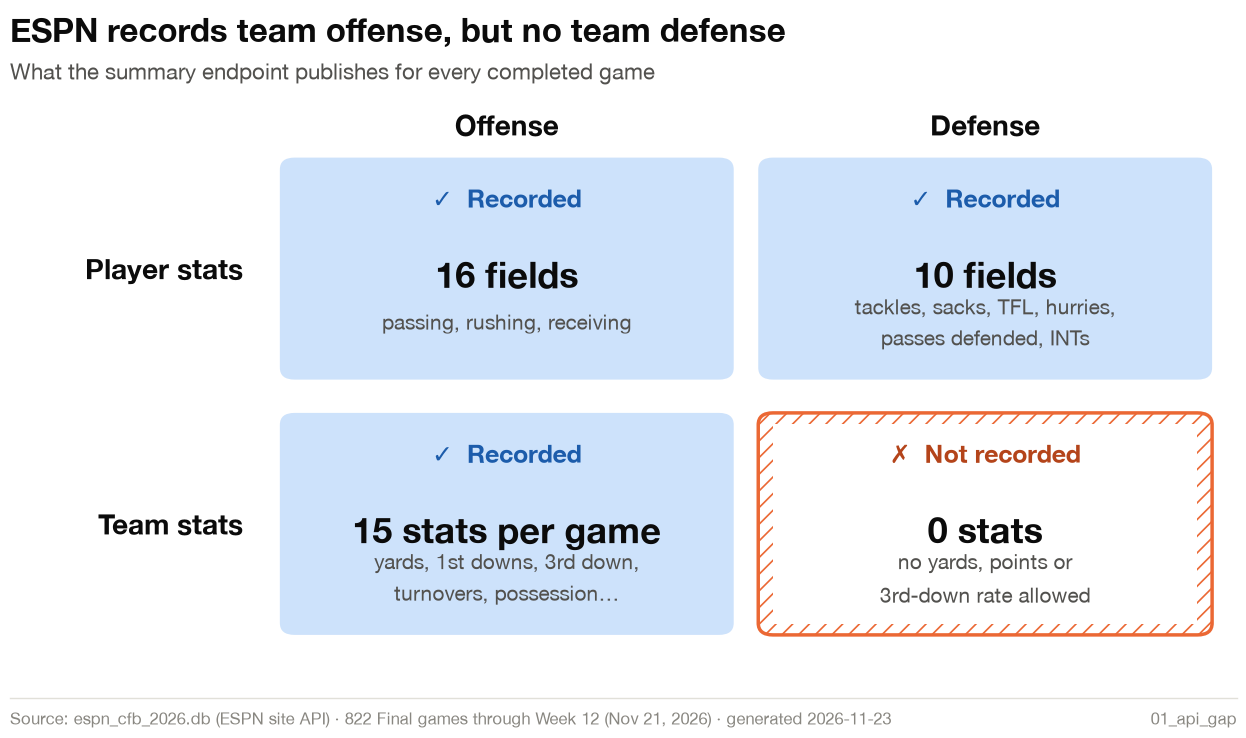

In [45]:
def fig_api_gap():
    fig = new_figure("ESPN records team offense, but no team defense",
                     "What the summary endpoint publishes for every completed game")
    ax = canvas(fig)
    col_x, row_y, cw, ch = (22, 61), (52, 6), 37, 40
    for x, label in zip(col_x, ("Offense", "Defense")):
        ax.text(x + cw / 2, 96, label, ha="center", fontsize=20, fontweight="bold", color=INK)
    for y, label in zip(row_y, ("Player stats", "Team stats")):
        ax.text(19, y + ch / 2, label, ha="right", va="center", fontsize=20, fontweight="bold", color=INK)
    cells = [
        (0, 0, True, f"{facts['player_offense_fields']} fields", "passing, rushing, receiving"),
        (1, 0, True, f"{facts['player_defense_fields']} fields", "tackles, sacks, TFL, hurries,\npasses defended, INTs"),
        (0, 1, True, f"{facts['team_stats_per_game']} stats per game", "yards, 1st downs, 3rd down,\nturnovers, possession…"),
        (1, 1, False, "0 stats", "no yards, points or\n3rd-down rate allowed"),
    ]
    for c, r, recorded, big, small in cells:
        x, y = col_x[c], row_y[r]
        if recorded:
            box(ax, x, y, cw, ch, fc=BLUE_LIGHT)
            mark, color = "✓  Recorded", BLUE_DARK
        else:
            missing_box(ax, x, y, cw, ch)
            mark, color = "✗  Not recorded", ORANGE_TEXT
        ax.text(x + cw / 2, y + ch - 9, mark, ha="center", fontsize=18, fontweight="bold", color=color)
        ax.text(x + cw / 2, y + ch / 2 - 1, big, ha="center", va="center", fontsize=26, fontweight="bold", color=INK)
        ax.text(x + cw / 2, y + 10, small, ha="center", va="center", fontsize=15, color=INK_2, linespacing=1.3)
    save(fig, "01_api_gap",
         "ESPN publishes team stats only for the offense and player stats for both sides, "
         "so team defense (yards, points and 3rd downs allowed) has to be reconstructed.")


fig_api_gap()

### Slide 3: excavating the API

The three endpoints and the parts of the game summary payload we use. Field counts come from the parsed tables.

02_api_payload_tree: Standings, scoreboard and game summary endpoints cover teams, schedule and every play; the summary's box score has team stats for the offense only.


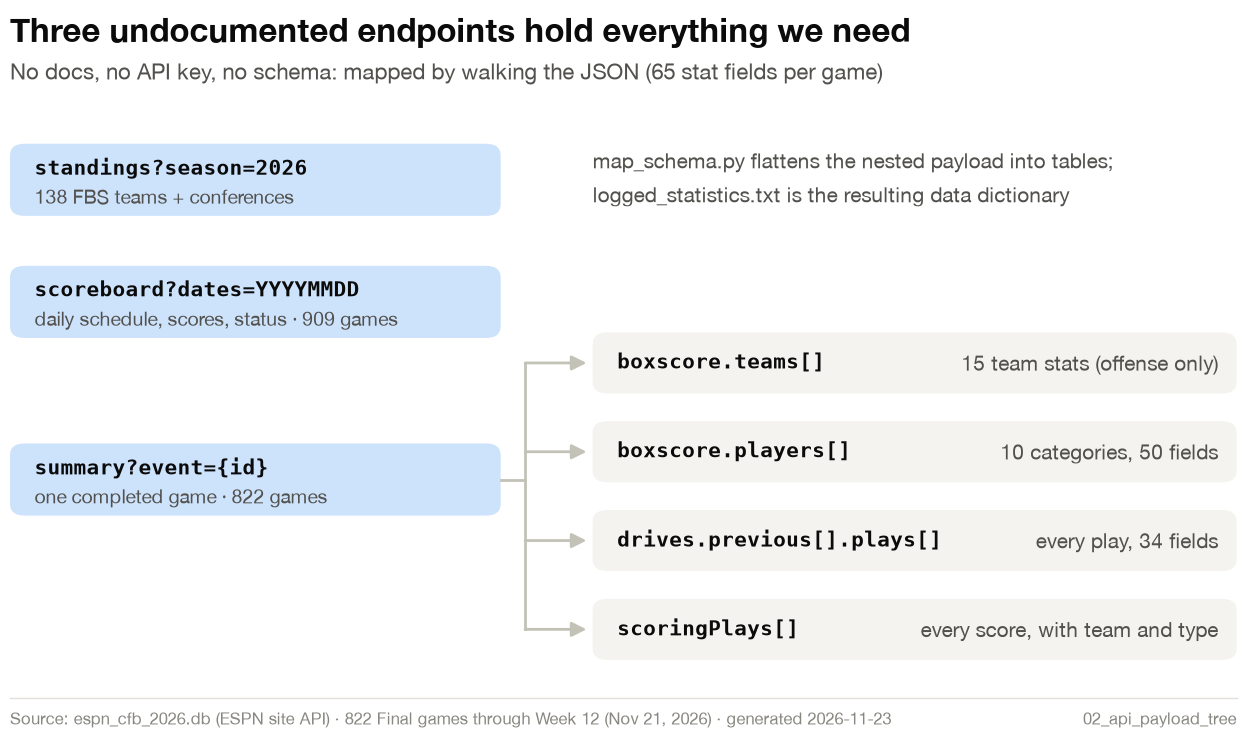

In [46]:
def fig_payload_tree():
    fig = new_figure("Three undocumented endpoints hold everything we need",
                     f"No docs, no API key, no schema: mapped by walking the JSON "
                     f"({facts['team_stats_per_game'] + facts['player_fields']} stat fields per game)")
    ax = canvas(fig)
    mono = dict(family="monospace", fontsize=15)
    endpoints = [
        (88, "standings?season=2026", f"{facts['fbs_teams']} FBS teams + conferences"),
        (66, "scoreboard?dates=YYYYMMDD", f"daily schedule, scores, status · {facts['games_scheduled']} games"),
        (34, "summary?event={id}", f"one completed game · {facts['games_final']} games"),
    ]
    for y, path, desc in endpoints:
        box(ax, 0, y - 6.5, 40, 13, fc=BLUE_LIGHT)
        ax.text(2, y + 2, path, color=INK, fontweight="bold", va="center", **mono)
        ax.text(2, y - 3, desc, color=INK_2, fontsize=14, va="center")
    children = [
        (55, "boxscore.teams[]", f"{facts['team_stats_per_game']} team stats (offense only)"),
        (39, "boxscore.players[]", f"{facts['player_categories']} categories, {facts['player_fields']} fields"),
        (23, "drives.previous[].plays[]", f"every play, {facts['play_columns']} fields"),
        (7, "scoringPlays[]", "every score, with team and type"),
    ]
    ax.plot([42, 42], [7, 55], color=AXIS, lw=2)
    ax.plot([40, 42], [34, 34], color=AXIS, lw=2)
    for y, key, desc in children:
        arrow(ax, 42, y, 47, y, color=AXIS)
        box(ax, 47.5, y - 5.5, 52.5, 11, fc=PANEL)
        ax.text(49.5, y, key, color=INK, fontweight="bold", va="center", **mono)
        ax.text(98.5, y, desc, color=INK_2, fontsize=15, va="center", ha="right")
    ax.text(47.5, 88, "map_schema.py flattens the nested payload into tables;\n"
                      "logged_statistics.txt is the resulting data dictionary",
            color=INK_2, fontsize=15, va="center", linespacing=1.4)
    save(fig, "02_api_payload_tree",
         "Standings, scoreboard and game summary endpoints cover teams, schedule and every play; "
         "the summary's box score has team stats for the offense only.")


fig_payload_tree()

### Slide 4: collection methods

Request counts: one standings call, one scoreboard call per stored day (`Scoreboard_Fetches`) and one summary call per stored game (`Raw_Boxscores`). This is the minimum cost of the season so far; refreshes of recent games add more.

03_collection_pipeline: Only three steps call ESPN (952 requests for the season so far); parsing and deriving rebuild every table from stored JSON with zero requests.


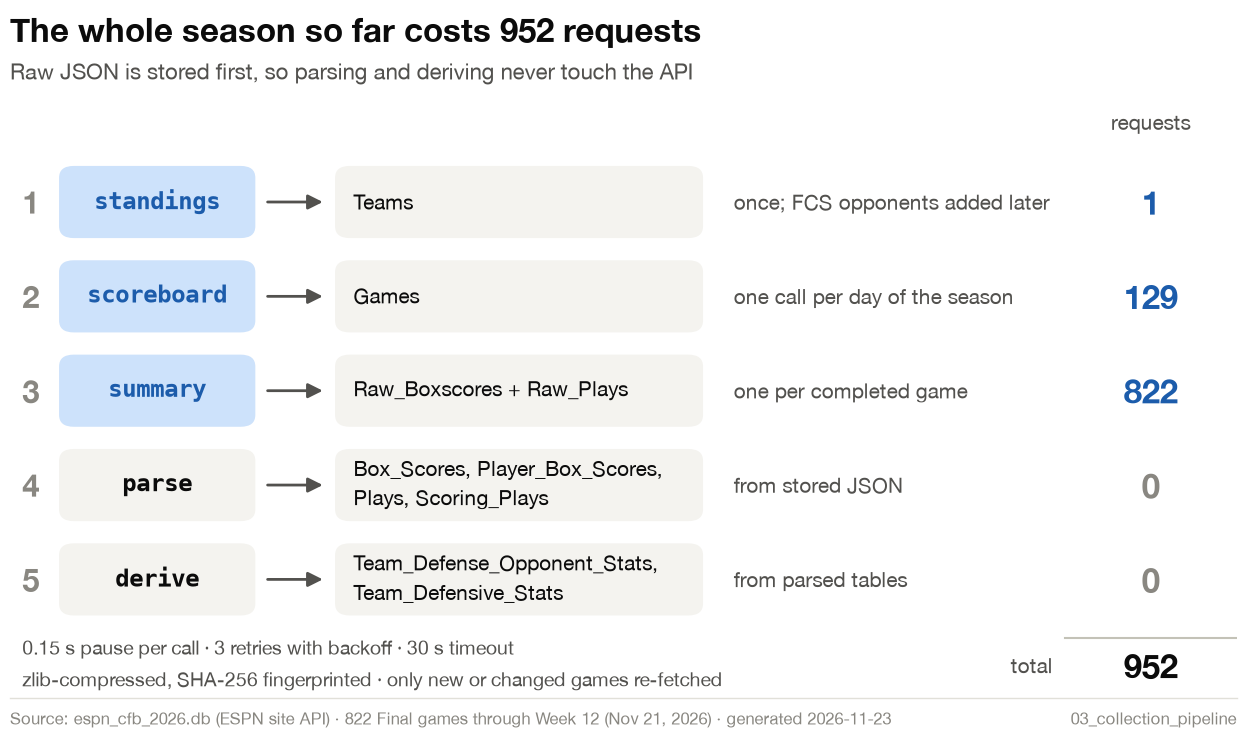

In [47]:
def fig_pipeline():
    fig = new_figure(f"The whole season so far costs {facts['requests']:,} requests",
                     "Raw JSON is stored first, so parsing and deriving never touch the API")
    ax = canvas(fig)
    rows = [
        ("1", "standings", "Teams", 1, "once; FCS opponents added later"),
        ("2", "scoreboard", "Games", facts["scoreboard_days"], "one call per day of the season"),
        ("3", "summary", "Raw_Boxscores + Raw_Plays", facts["summaries"], "one per completed game"),
        ("4", "parse", "Box_Scores, Player_Box_Scores,\nPlays, Scoring_Plays", 0, "from stored JSON"),
        ("5", "derive", "Team_Defense_Opponent_Stats,\nTeam_Defensive_Stats", 0, "from parsed tables"),
    ]
    ax.text(93, 97, "requests", ha="center", fontsize=15, color=INK_2)
    for i, (step, src, dst, n, note) in enumerate(rows):
        y = 84 - i * 17
        fetch = n > 0
        ax.text(1, y, step, fontsize=22, fontweight="bold", color=MUTED, va="center")
        box(ax, 4, y - 6.5, 16, 13, fc=BLUE_LIGHT if fetch else PANEL)
        ax.text(12, y, src, ha="center", va="center", fontsize=17, fontweight="bold",
                color=BLUE_DARK if fetch else INK, family="monospace")
        arrow(ax, 21, y, 25.5, y)
        box(ax, 26.5, y - 6.5, 30, 13, fc=PANEL)
        ax.text(28, y, dst, va="center", fontsize=15, color=INK, linespacing=1.2)
        ax.text(59, y, note, va="center", fontsize=15, color=INK_2)
        ax.text(93, y, f"{n:,}", ha="center", va="center", fontsize=24, fontweight="bold",
                color=BLUE_DARK if fetch else MUTED)
    ax.plot([86, 100], [5.5, 5.5], color=AXIS, lw=1.5)
    ax.text(85, 0.5, "total", ha="right", va="center", fontsize=15, color=INK_2)
    ax.text(93, 0.5, f"{facts['requests']:,}", ha="center", va="center", fontsize=24, fontweight="bold", color=INK)
    ax.text(1, 0.5, "0.15 s pause per call · 3 retries with backoff · 30 s timeout\n"
                    "zlib-compressed, SHA-256 fingerprinted · only new or changed games re-fetched",
            va="center", fontsize=14, color=INK_2, linespacing=1.4)
    save(fig, "03_collection_pipeline",
         f"Only three steps call ESPN ({facts['requests']:,} requests for the season so far); "
         "parsing and deriving rebuild every table from stored JSON with zero requests.")


fig_pipeline()

### Slide 5: what we collected

04_collection_tiles: 822 completed games yield 419,826 player stat rows and 146,310 plays, all stored in one espn_cfb_2026.db file.


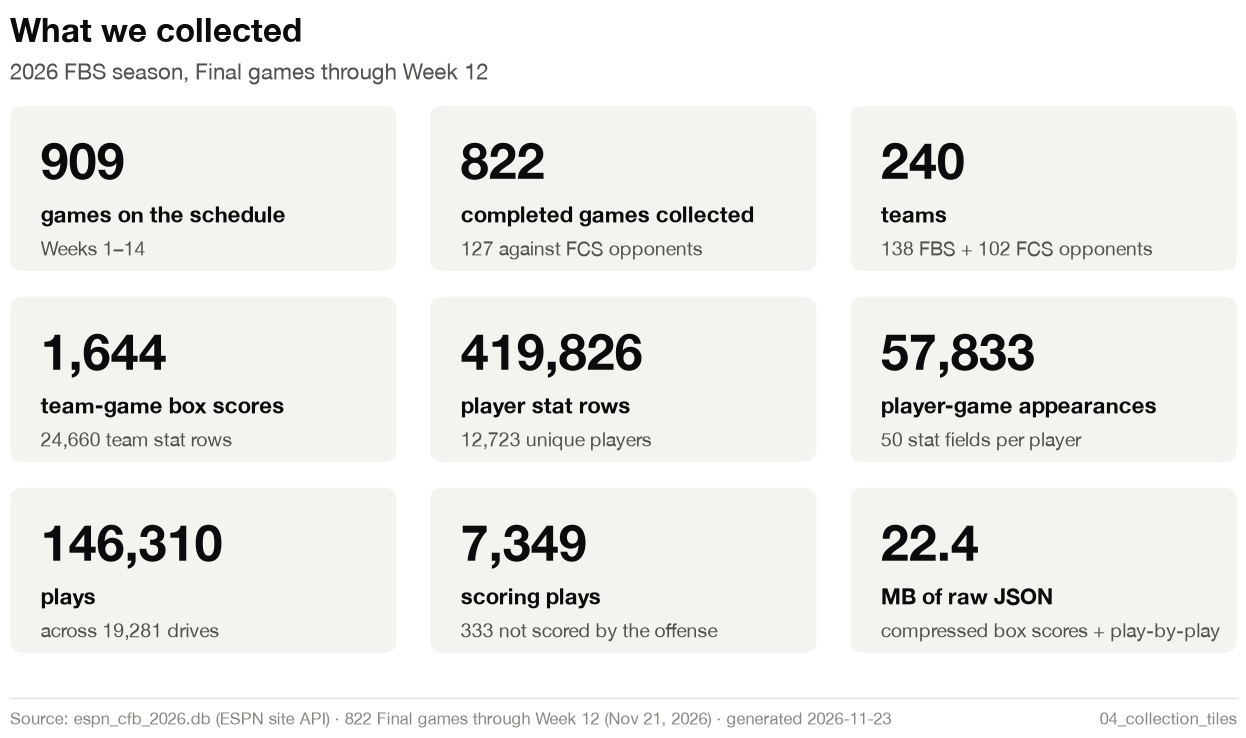

In [48]:
def fig_collection_tiles():
    fig = new_figure("What we collected", f"{YEAR} FBS season, Final games through Week {facts['max_week_final']}")
    tiles = [
        (facts["games_scheduled"], "games on the schedule", f"Weeks 1–{facts['max_week_scheduled']}"),
        (facts["games_final"], "completed games collected", f"{facts['games_vs_fcs']} against FCS opponents"),
        (facts["teams"], "teams", f"{facts['fbs_teams']} FBS + {facts['teams'] - facts['fbs_teams']} FCS opponents"),
        (facts["team_games"], "team-game box scores", f"{facts['box_rows']:,} team stat rows"),
        (facts["player_rows"], "player stat rows", f"{facts['players']:,} unique players"),
        (facts["player_games"], "player-game appearances", f"{facts['player_fields']} stat fields per player"),
        (facts["plays"], "plays", f"across {facts['drives']:,} drives"),
        (facts["scoring_plays"], "scoring plays", f"{facts['non_offense_scores']} not scored by the offense"),
        (round(facts["raw_mb"], 1), "MB of raw JSON", "compressed box scores + play-by-play"),
    ]
    ax = canvas(fig, (0.04, 0.09, 0.92, 0.76))
    w, h, gx, gy = 31.5, 29, 2.75, 4.5
    for i, (value, label, detail) in enumerate(tiles):
        r, c = divmod(i, 3)
        x, y = c * (w + gx), 100 - (r + 1) * h - r * gy
        box(ax, x, y, w, h, fc=PANEL)
        ax.text(x + 2.5, y + h - 9.5, f"{value:,}", fontsize=36, fontweight="bold", color=INK, va="center")
        ax.text(x + 2.5, y + 10, label, fontsize=16, fontweight="bold", color=INK, va="center")
        ax.text(x + 2.5, y + 4, detail, fontsize=14, color=INK_2, va="center")
    save(fig, "04_collection_tiles",
         f"{facts['games_final']} completed games yield {facts['player_rows']:,} player stat rows and "
         f"{facts['plays']:,} plays, all stored in one {DB_FILE} file.")


fig_collection_tiles()

### Slide 6: reconstructing team defense

Three figures: how the four sources combine, a before/after count, and one real game worked through both methods.

05_reconstruction_flow: Opponent box scores, the scoreboard, scoring plays and player box scores combine into 27 team defensive stats for each of 1,644 team-games.


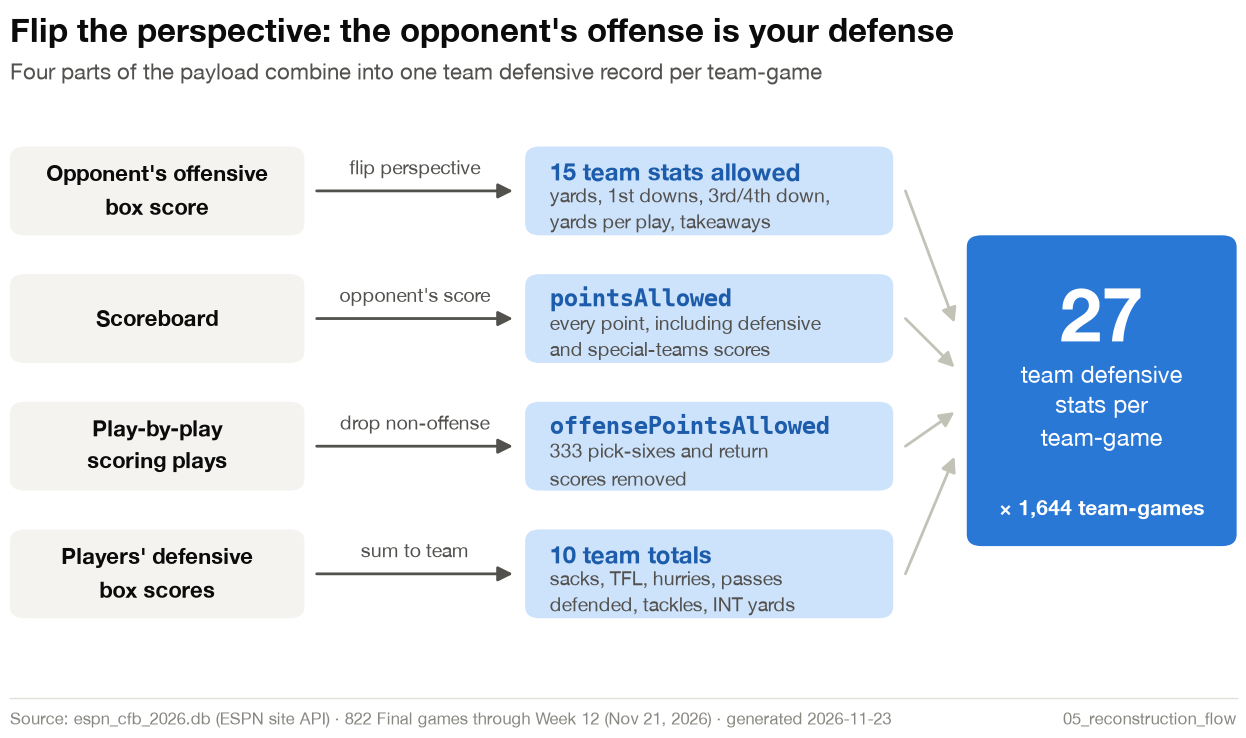

06_before_after: ESPN publishes no team defensive stats; we reconstructed 17 plus 10 player totals per team-game and 63 season features per team.


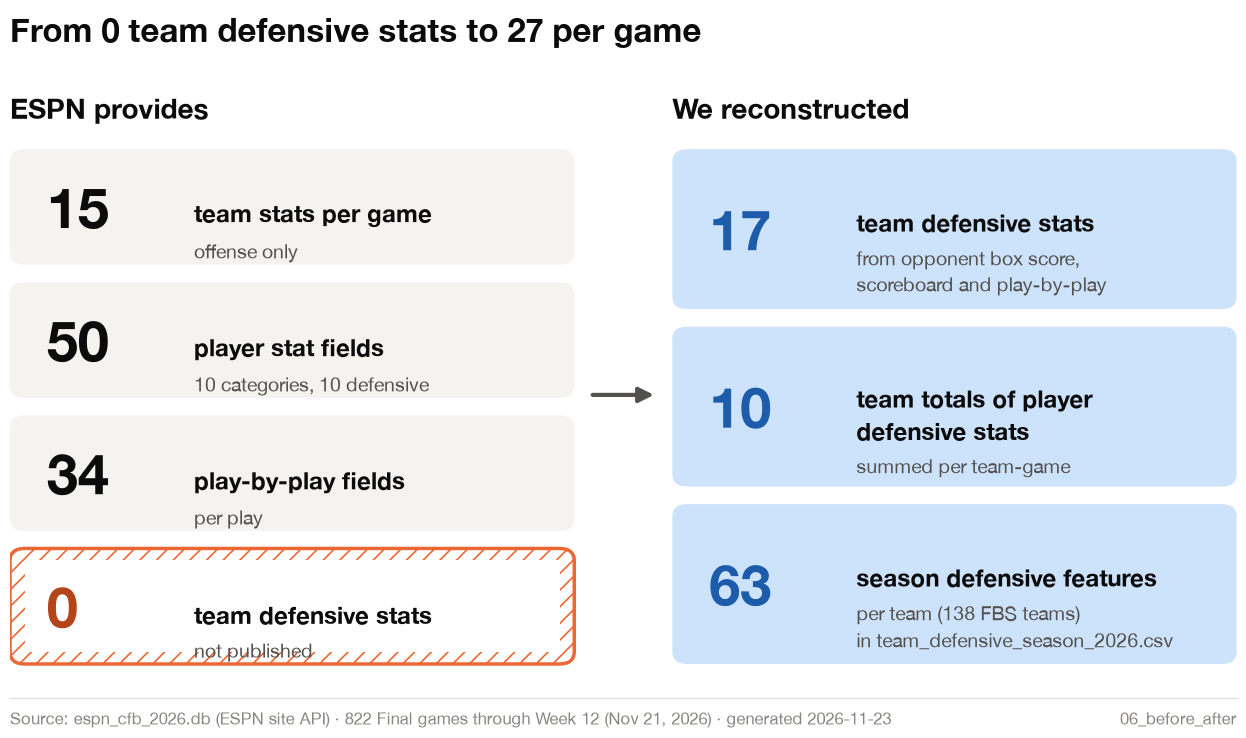

07_worked_example: In Alabama at Tennessee, Alabama's offensive box score becomes Tennessee's "allowed" line, and 9 Tennessee defenders sum to 5 sacks, 10 TFL and 4 passes defended.


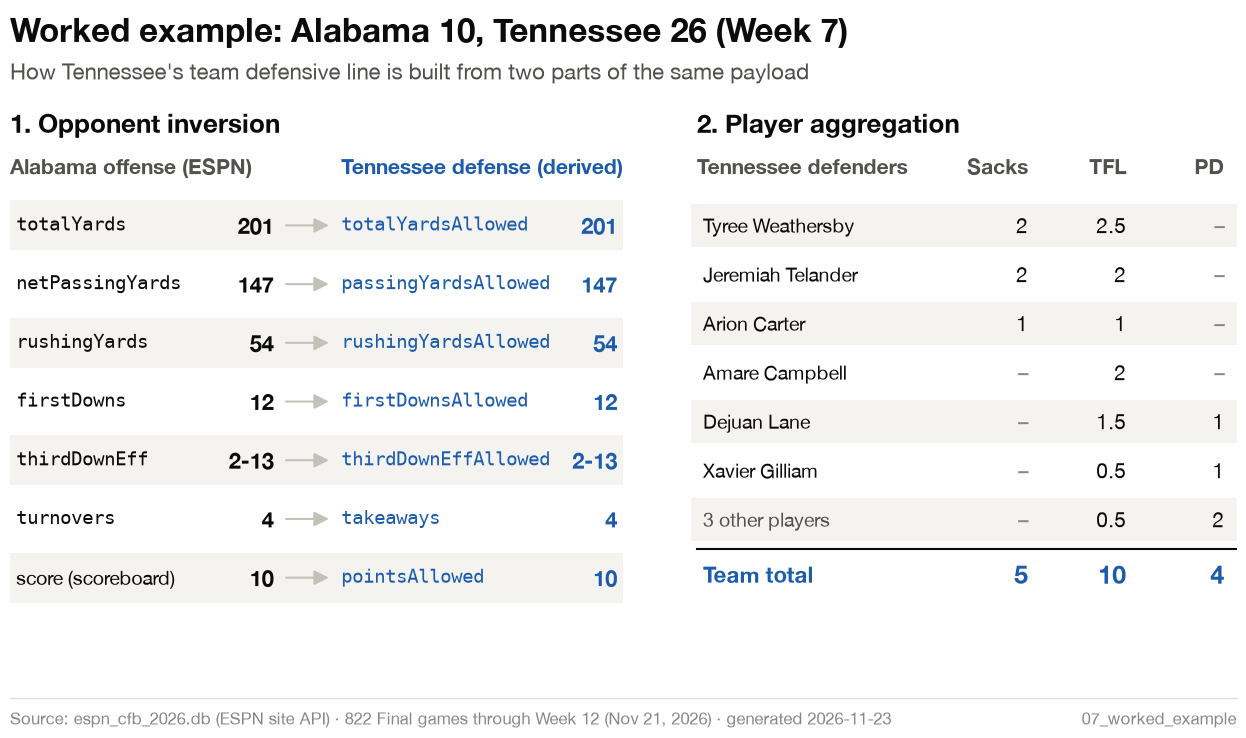

In [49]:
def fig_reconstruction_flow():
    fig = new_figure("Flip the perspective: the opponent's offense is your defense",
                     "Four parts of the payload combine into one team defensive record per team-game")
    ax = canvas(fig)
    rows = [
        ("Opponent's offensive\nbox score", "flip perspective", f"{facts['opp_stats'] - 2} team stats allowed",
         "yards, 1st downs, 3rd/4th down,\nyards per play, takeaways"),
        ("Scoreboard", "opponent's score", "pointsAllowed", "every point, including defensive\nand special-teams scores"),
        ("Play-by-play\nscoring plays", "drop non-offense", "offensePointsAllowed",
         f"{facts['non_offense_scores']} pick-sixes and return\nscores removed"),
        ("Players' defensive\nbox scores", "sum to team", f"{facts['player_team_stats']} team totals",
         "sacks, TFL, hurries, passes\ndefended, tackles, INT yards"),
    ]
    for i, (src, how, out, detail) in enumerate(rows):
        y = 86 - i * 23
        box(ax, 0, y - 8, 24, 16, fc=PANEL)
        ax.text(12, y, src, ha="center", va="center", fontsize=16, fontweight="bold", color=INK, linespacing=1.2)
        arrow(ax, 25, y, 41, y)
        ax.text(33, y + 3, how, ha="center", fontsize=14, color=INK_2)
        box(ax, 42, y - 8, 30, 16, fc=BLUE_LIGHT)
        ax.text(44, y + 3.5, out, va="center", fontsize=17, fontweight="bold", color=BLUE_DARK,
                family="monospace" if out[0].islower() else None)
        ax.text(44, y - 3.5, detail, va="center", fontsize=14, color=INK_2, linespacing=1.15)
        arrow(ax, 73, y, 77, 50 + (y - 51) * 0.35, color=AXIS)
    box(ax, 78, 22, 22, 56, fc=BLUE)
    ax.text(89, 64, f"{facts['derived_stats']}", ha="center", va="center", fontsize=54, fontweight="bold", color="white")
    ax.text(89, 47, "team defensive\nstats per\nteam-game", ha="center", va="center", fontsize=17,
            color="white", linespacing=1.2)
    ax.text(89, 29, f"× {facts['team_games']:,} team-games", ha="center", va="center", fontsize=15,
            color="white", fontweight="bold")
    save(fig, "05_reconstruction_flow",
         f"Opponent box scores, the scoreboard, scoring plays and player box scores combine into "
         f"{facts['derived_stats']} team defensive stats for each of {facts['team_games']:,} team-games.")


def fig_before_after():
    fig = new_figure(f"From 0 team defensive stats to {facts['derived_stats']} per game")
    ax = canvas(fig, (0.04, 0.09, 0.92, 0.78))
    left = [
        (facts["team_stats_per_game"], "team stats per game", "offense only"),
        (facts["player_fields"], "player stat fields",
         f"{facts['player_categories']} categories, {facts['player_defense_fields']} defensive"),
        (facts["play_columns"], "play-by-play fields", "per play"),
        (0, "team defensive stats", "not published"),
    ]
    right = [
        (facts["opp_stats"], "team defensive stats", "from opponent box score,\nscoreboard and play-by-play"),
        (facts["player_team_stats"], "team totals of player\ndefensive stats", "summed per team-game"),
        (facts["season_features"], "season defensive features",
         f"per team ({len(season_rollup)} FBS teams)\nin {ROLLUP_OUTPUT}"),
    ]
    for x, title, items in ((0, "ESPN provides", left), (54, "We reconstructed", right)):
        ax.text(x, 97, title, fontsize=20, fontweight="bold", color=INK, va="center")
        h = (88 - (len(items) - 1) * 3) / len(items)
        for i, (value, label, note) in enumerate(items):
            y = 90 - (i + 1) * h - i * 3
            if value == 0:
                missing_box(ax, x, y, 46, h)
                color = ORANGE_TEXT
            else:
                box(ax, x, y, 46, h, fc=BLUE_LIGHT if x else PANEL)
                color = BLUE_DARK if x else INK
            ax.text(x + 3, y + h / 2, f"{value}", fontsize=40, fontweight="bold", va="center", color=color)
            label_lines = label.count("\n") + 1
            note_lines = note.count("\n") + 1
            top = y + h / 2 + (label_lines + note_lines - 2) * 2.6
            ax.text(x + 15, top + 1, label, fontsize=17, fontweight="bold", color=INK, va="top", linespacing=1.1)
            ax.text(x + 15, top - label_lines * 5.2 - 0.5, note, fontsize=14, color=INK_2, va="top", linespacing=1.15)
    arrow(ax, 47.5, 48, 52.5, 48, color=INK_2, lw=3)
    save(fig, "06_before_after",
         f"ESPN publishes no team defensive stats; we reconstructed {facts['opp_stats']} plus "
         f"{facts['player_team_stats']} player totals per team-game and {facts['season_features']} "
         f"season features per team.")


def fig_worked_example():
    game = pd.read_sql_query("SELECT * FROM Games WHERE game_id = ?", conn, params=(WORKED_GAME_ID,)).iloc[0]
    defense = CASE_TEAM_ID
    offense = game.away_team_id if game.home_team_id == defense else game.home_team_id
    home, away = short_names[game.home_team_id], short_names[game.away_team_id]

    # Opponent inversion: the offense's box score next to the defense's derived "allowed" line.
    pairs_shown = [("totalYards", "totalYardsAllowed"), ("netPassingYards", "passingYardsAllowed"),
                   ("rushingYards", "rushingYardsAllowed"), ("firstDowns", "firstDownsAllowed"),
                   ("thirdDownEff", "thirdDownEffAllowed"), ("turnovers", "takeaways")]
    off = pd.read_sql_query("SELECT stat_name, display_value FROM Box_Scores WHERE game_id = ? AND team_id = ?",
                            conn, params=(WORKED_GAME_ID, offense)).set_index("stat_name")["display_value"]
    allowed = pd.read_sql_query("SELECT stat_name, display_value FROM Team_Defense_Opponent_Stats "
                                "WHERE game_id = ? AND team_id = ?", conn,
                                params=(WORKED_GAME_ID, defense)).set_index("stat_name")["display_value"]

    # Player aggregation: the defense's players summed to team totals.
    shown_stats = ["sacks", "tacklesForLoss", "passesDefended"]
    wide = pd.read_sql_query("""
        SELECT player_name, stat_name, stat_value FROM Player_Box_Scores
        WHERE game_id = ? AND team_id = ? AND stat_category = 'defensive'
          AND stat_name IN ('sacks', 'tacklesForLoss', 'passesDefended')""",
        conn, params=(WORKED_GAME_ID, defense)
    ).pivot_table(index="player_name", columns="stat_name", values="stat_value", aggfunc="sum")[shown_stats].fillna(0)
    wide = wide[(wide > 0).any(axis=1)].sort_values(shown_stats, ascending=False)
    team_totals = pd.read_sql_query(
        "SELECT stat_name, team_total FROM Team_Defensive_Stats WHERE game_id = ? AND team_id = ?",
        conn, params=(WORKED_GAME_ID, defense)).set_index("stat_name")["team_total"][shown_stats]
    assert np.allclose(wide.sum(), team_totals), "player rows do not sum to the team total"

    fig = new_figure(f"Worked example: {away} {game.away_score}, {home} {game.home_score} (Week {game.week})",
                     f"How {short_names[defense]}'s team defensive line is built from two parts of the same payload")
    ax = canvas(fig, (0.04, 0.09, 0.92, 0.76))

    ax.text(0, 97, "1. Opponent inversion", fontsize=19, fontweight="bold", color=INK, va="center")
    ax.text(0, 88, f"{short_names[offense]} offense (ESPN)", fontsize=15, color=INK_2, fontweight="bold")
    ax.text(27, 88, f"{short_names[defense]} defense (derived)", fontsize=15, color=BLUE_DARK, fontweight="bold")
    rows = [(s, off[s], d) for s, d in pairs_shown] + [("score (scoreboard)", allowed["pointsAllowed"], "pointsAllowed")]
    for i, (src, value, dst) in enumerate(rows):
        y = 79 - i * 10.3
        if i % 2 == 0:
            ax.add_patch(Rectangle((-0.5, y - 4.4), 50.5, 8.8, fc=PANEL, ec="none"))
        ax.text(0.5, y, src, fontsize=14, family="monospace" if " " not in src else None, color=INK, va="center")
        ax.text(21.5, y, value, fontsize=16, fontweight="bold", color=INK, va="center", ha="right")
        arrow(ax, 22.5, y, 26, y, color=AXIS, lw=1.5)
        ax.text(27, y, dst, fontsize=14, family="monospace", color=BLUE_DARK, va="center")
        ax.text(49.5, y, allowed[dst], fontsize=16, fontweight="bold", color=BLUE_DARK, va="center", ha="right")

    x0, cx = 56, [83, 91, 99]
    ax.text(x0, 97, "2. Player aggregation", fontsize=19, fontweight="bold", color=INK, va="center")
    ax.text(x0, 88, f"{short_names[defense]} defenders", fontsize=15, color=INK_2, fontweight="bold")
    for x, label in zip(cx, ("Sacks", "TFL", "PD")):
        ax.text(x, 88, label, fontsize=15, color=INK_2, fontweight="bold", ha="right")
    body = list(wide.head(6).iterrows())
    if len(wide) > 6:
        body.append((f"{len(wide) - 6} other players", wide.iloc[6:].sum()))
    for i, (name, r) in enumerate(body):
        y = 79 - i * 8.6
        if i % 2 == 0:
            ax.add_patch(Rectangle((x0 - 0.5, y - 3.8), 44.5, 7.6, fc=PANEL, ec="none"))
        ax.text(x0 + 0.5, y, name, fontsize=14, color=INK_2 if "other" in name else INK, va="center")
        for x, stat in zip(cx, shown_stats):
            ax.text(x, y, fmt(r[stat]) if r[stat] else "–", fontsize=15, color=INK if r[stat] else MUTED,
                    va="center", ha="right")
    y = 79 - len(body) * 8.6 - 1
    ax.plot([x0, x0 + 44], [y + 4.5, y + 4.5], color=INK, lw=1.5)
    ax.text(x0 + 0.5, y, "Team total", fontsize=16, fontweight="bold", color=BLUE_DARK, va="center")
    for x, stat in zip(cx, shown_stats):
        ax.text(x, y, fmt(team_totals[stat]), fontsize=18, fontweight="bold", color=BLUE_DARK, va="center", ha="right")
    save(fig, "07_worked_example",
         f"In {away} at {home}, {short_names[offense]}'s offensive box score becomes {short_names[defense]}'s "
         f"\"allowed\" line, and {len(wide)} {short_names[defense]} defenders sum to "
         f"{fmt(team_totals['sacks'])} sacks, {fmt(team_totals['tacklesForLoss'])} TFL and "
         f"{fmt(team_totals['passesDefended'])} passes defended.")


fig_reconstruction_flow()
fig_before_after()
fig_worked_example()

### Slide 7: validation and context recovery

The agreement plots and checklist reuse the DataFrames from section 2 (`int_check`, `fumble_check`, `sack_check`, `pbp_summary`, `rule_rows`, `points_allowed`, `coverage`, `missing_fbs`). The scoring-play check is new here: each team's scoring plays are summed and compared with its scoreboard score. Because `pointsAllowed` comes from the scoreboard, this is the only points check that uses an independent source.

Scoring-play mismatches: 3


,game_id,team_id,scoreboard,plays,team
58,401862694,2429,41,34,Charlotte
277,401856816,66,17,11,Iowa State
1638,401858308,24,44,43,Stanford


Every mismatch falls back to pointsAllowed: True
08_validation_agreement: Out of 1,644 team-games, the two sources agree exactly on interceptions in 1,644, fumble recoveries in 1,635, sacks in 1,549 and points in 1,641.


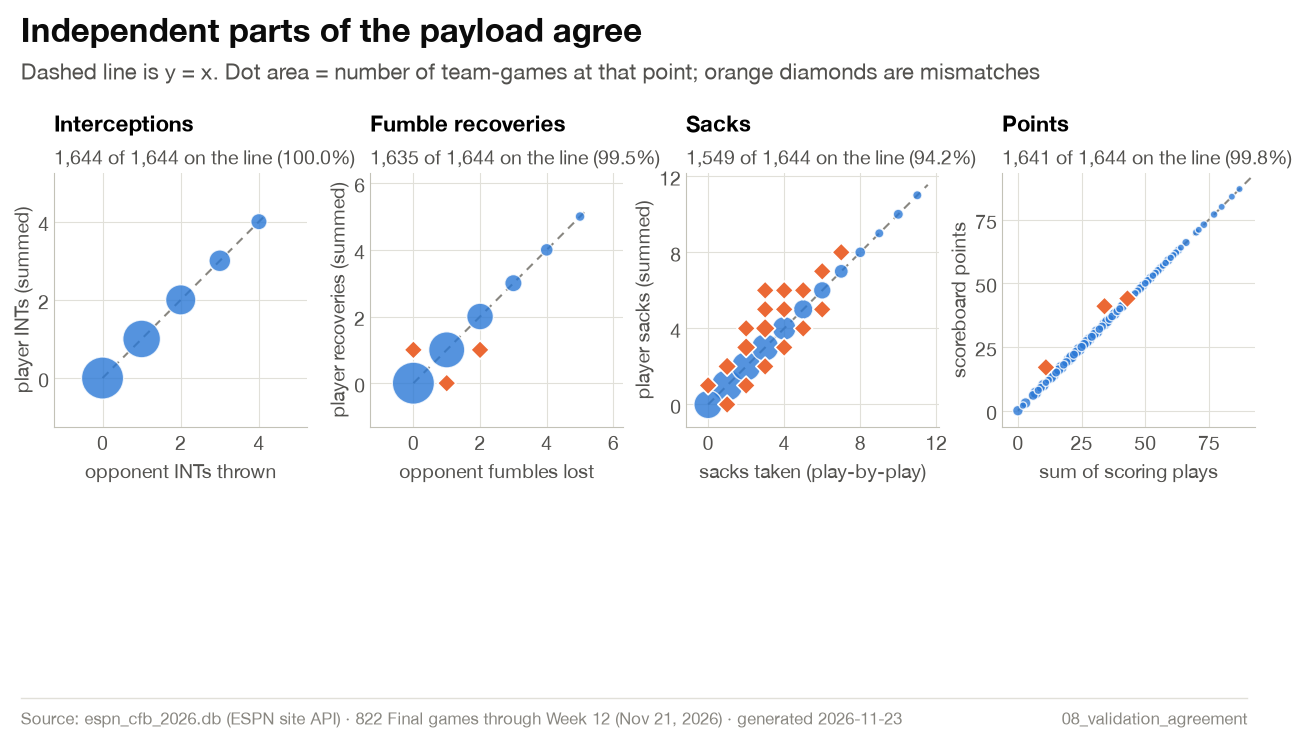

09_validation_checklist: 6 of 7 validation checks pass exactly or are fully explained; the exception (player sacks = sacks taken (play-by-play)) shows small disagreements between ESPN's own sources.


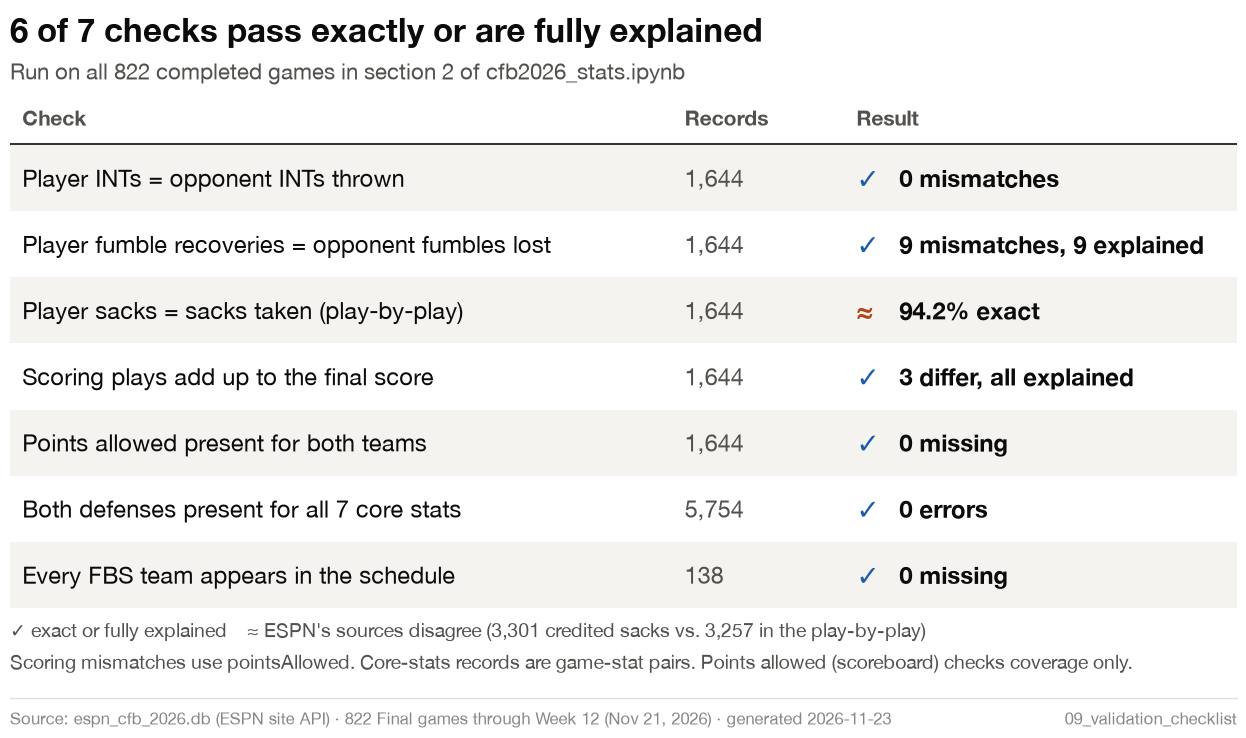

10_context_recovery: 9 of 9 fumble mismatches are explained by the play text (7 touchbacks, 1 own-fumble recovery, 1 muffed punt), and three play-text fixes raise exact sack agreement from 85.8% to 94.2%.


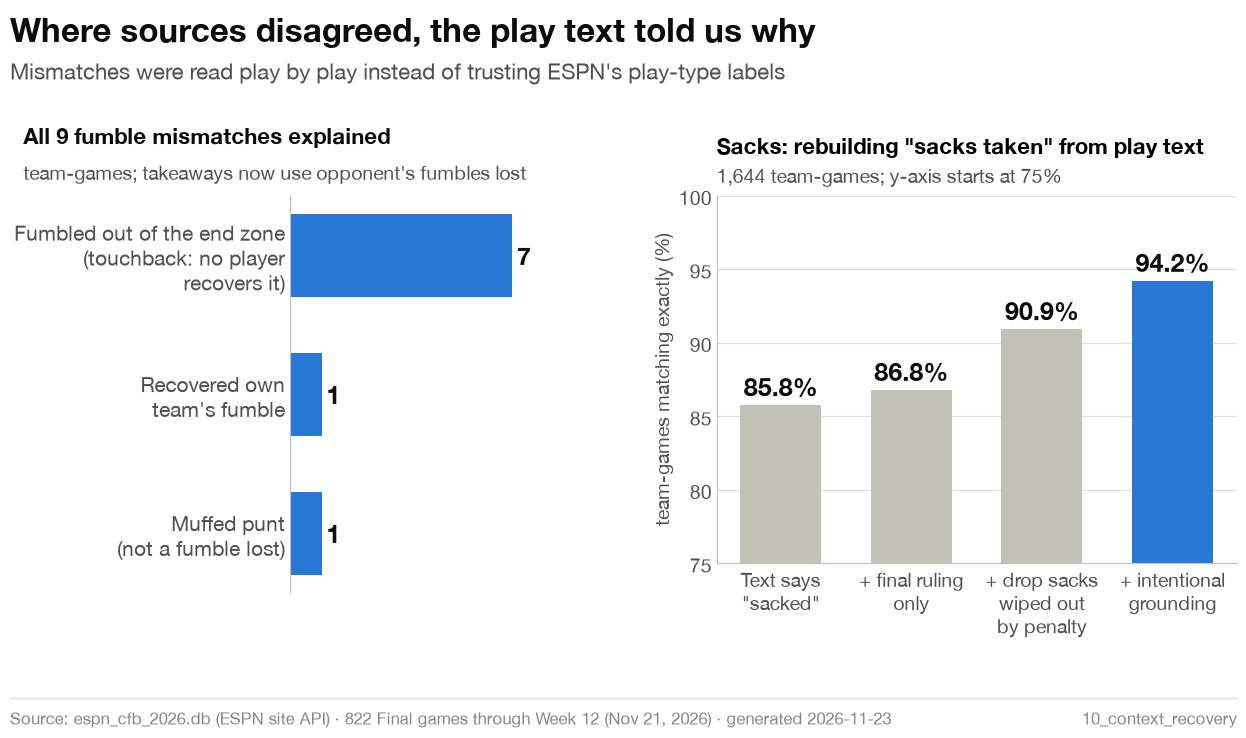

In [50]:
# Scoreboard points vs. the sum of that team's scoring plays, per team-game.
scoring_check = pd.read_sql_query("""
    WITH sides AS (
        SELECT game_id, home_team_id AS team_id, home_score AS scoreboard FROM Games WHERE status = 'Final'
        UNION ALL
        SELECT game_id, away_team_id, away_score FROM Games WHERE status = 'Final'),
    scored AS (SELECT game_id, team_id, SUM(points) AS plays FROM Scoring_Plays GROUP BY game_id, team_id)
    SELECT s.game_id, s.team_id, s.scoreboard, COALESCE(scored.plays, 0) AS plays
    FROM sides s LEFT JOIN scored USING (game_id, team_id)""", conn)
scoring_mismatches = scoring_check[scoring_check.plays != scoring_check.scoreboard]
print("Scoring-play mismatches:", len(scoring_mismatches))
display(scoring_mismatches.assign(team=scoring_mismatches.team_id.map(short_names)))

# The derivation drops offensePointsAllowed when a game's scoring plays don't reconcile, and those
# team-games fall back to pointsAllowed. A mismatch is explained if it is one of them (keyed by the scoring team).
fallback_games = pd.read_sql_query("""
    SELECT game_id, opponent_id AS team_id FROM Team_Defense_Opponent_Stats
    GROUP BY game_id, team_id, opponent_id
    HAVING SUM(stat_name = 'offensePointsAllowed') = 0""", conn)
scoring_explained = (set(zip(scoring_mismatches.game_id, scoring_mismatches.team_id))
                     <= set(zip(fallback_games.game_id, fallback_games.team_id)))
print("Every mismatch falls back to pointsAllowed:", scoring_explained)


def agreement_panel(ax, x, y, title, xlabel, ylabel, step=1.0, max_area=900):
    d = pd.DataFrame({"x": np.round(np.asarray(x, float) / step) * step,
                      "y": np.round(np.asarray(y, float) / step) * step})
    counts = d.value_counts().rename("n").reset_index()
    on = counts.x == counts.y
    hi = max(counts.x.max(), counts.y.max())
    ax.plot([0, hi * 1.05], [0, hi * 1.05], color=MUTED, lw=1.5, ls=(0, (4, 3)), zorder=1)
    area = 20 + max_area * np.sqrt(counts.n / counts.n.max())
    ax.scatter(counts.x[on], counts.y[on], s=area[on], color=BLUE, alpha=0.8, edgecolor="white", linewidth=1, zorder=2)
    ax.scatter(counts.x[~on], counts.y[~on], s=area[~on].clip(lower=90), color=ORANGE, marker="D",
               edgecolor="white", linewidth=1.2, zorder=3)
    match = int((d.x == d.y).sum())
    ax.set_title(title, pad=30)
    ax.text(0, 1.035, f"{match:,} of {len(d):,} on the line ({match / len(d):.1%})", transform=ax.transAxes,
            fontsize=14, color=INK_2)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    pad = hi * 0.06 + step
    ax.set_xlim(-pad, hi + pad)
    ax.set_ylim(-pad, hi + pad)
    ax.set_aspect("equal")
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(4, integer=True))
    ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(4, integer=True))
    style_axes(ax, "both")


def fig_validation_agreement():
    fig = new_figure("Independent parts of the payload agree",
                     "Dashed line is y = x. Dot area = number of team-games at that point; orange diamonds are mismatches")
    panels = [
        ("Interceptions", int_check.opponent_interceptions_thrown, int_check.player_interceptions,
         "opponent INTs thrown", "player INTs (summed)", 1, 900),
        ("Fumble recoveries", fumble_check.opponent_fumbles_lost, fumble_check.player_recoveries,
         "opponent fumbles lost", "player recoveries (summed)", 1, 900),
        ("Sacks", sack_check.pbp_sacks_taken, sack_check.player_sacks,
         "sacks taken (play-by-play)", "player sacks (summed)", 0.5, 500),
        ("Points", scoring_check.plays, scoring_check.scoreboard,
         "sum of scoring plays", "scoreboard points", 1, 60),
    ]
    for i, (title, x, y, xl, yl, step, area) in enumerate(panels):
        ax = fig.add_axes((0.065 + i * 0.237, 0.12, 0.19, 0.64))
        ax.set_anchor("N")
        agreement_panel(ax, x, y, title, xl, yl, step, area)
    on_line = [int((np.round(np.asarray(x, float) / step) == np.round(np.asarray(y, float) / step)).sum())
               for _, x, y, _, _, step, _ in panels]
    save(fig, "08_validation_agreement",
         f"Out of {facts['team_games']:,} team-games, the two sources agree exactly on interceptions in {on_line[0]:,}, "
         f"fumble recoveries in {on_line[1]:,}, sacks in {on_line[2]:,} and points in {on_line[3]:,}.")


def fig_validation_checklist():
    fumble_mismatches = int((~fumble_check.matches).sum())
    explained = int((pbp_summary.status == "Explained").sum())
    rows = [
        ("Player INTs = opponent INTs thrown", f"{len(int_check):,}",
         f"{int((~int_check.matches).sum())} mismatches", True),
        ("Player fumble recoveries = opponent fumbles lost", f"{len(fumble_check):,}",
         f"{fumble_mismatches} mismatches, {explained} explained", explained == fumble_mismatches),
        ("Player sacks = sacks taken (play-by-play)", f"{len(sack_check):,}",
         f"{(sack_check.difference == 0).mean():.1%} exact", False),
        ("Scoring plays add up to the final score", f"{len(scoring_check):,}",
         f"{len(scoring_mismatches)} differ" + (", all explained" if scoring_explained and len(scoring_mismatches) else ""),
         scoring_explained),
        ("Points allowed present for both teams", f"{len(points_allowed):,}",
         f"{int(points_allowed.points_allowed.isna().sum())} missing", True),
        ("Both defenses present for all 7 core stats", f"{len(coverage):,}",
         f"{len(bad_coverage) + len(missing_pairs)} errors", True),
        ("Every FBS team appears in the schedule", f"{len(fbs_teams)}", f"{len(missing_fbs)} missing", True),
    ]
    clean = sum(exact for *_, exact in rows)
    fig = new_figure(f"{clean} of {len(rows)} checks pass exactly or are fully explained",
                     f"Run on all {facts['games_final']} completed games in section 2 of cfb{YEAR}_stats.ipynb")
    ax = canvas(fig, (0.04, 0.155, 0.92, 0.70))
    for x, label in ((1, "Check"), (55, "Records"), (69, "Result")):
        ax.text(x, 97, label, fontsize=15, fontweight="bold", color=INK_2, va="center")
    ax.plot([0, 100], [92, 92], color=INK, lw=1.2)
    h = 12.6
    for i, (check, n, result, exact) in enumerate(rows):
        y = 85.5 - i * h
        if i % 2 == 0:
            ax.add_patch(Rectangle((0, y - h / 2), 100, h, fc=PANEL, ec="none"))
        ax.text(1, y, check, fontsize=17, color=INK, va="center")
        ax.text(55, y, n, fontsize=17, color=INK_2, va="center")
        mark, color = ("✓", BLUE_DARK) if exact else ("≈", ORANGE_TEXT)
        ax.text(69, y, mark, fontsize=20, fontweight="bold", color=color, va="center")
        ax.text(72.5, y, result, fontsize=17, fontweight="bold", color=INK, va="center")
    ax.text(0, -4, f"✓ exact or fully explained    ≈ ESPN's sources disagree ({fmt(sack_check.player_sacks.sum())} "
                   f"credited sacks vs. {fmt(sack_check.pbp_sacks_taken.sum())} in the play-by-play)\n"
                   f"Scoring mismatches use pointsAllowed. Core-stats records are game-stat pairs. "
                   f"Points allowed (scoreboard) checks coverage only.",
            fontsize=14, color=INK_2, va="center", linespacing=1.4)
    unclear = [check for check, _, _, exact in rows if not exact]
    save(fig, "09_validation_checklist",
         f"{clean} of {len(rows)} validation checks pass exactly or are fully explained"
         + (f"; the {'exception' if len(unclear) == 1 else 'exceptions'} "
            f"({'; '.join(u.lower() for u in unclear)}) {'shows' if len(unclear) == 1 else 'show'} "
            f"small disagreements between ESPN's own sources." if unclear else "."))


def fig_context_recovery():
    explanation = pbp_summary.explanation.fillna("")
    fumble_causes = [
        ("Fumbled out of the end zone\n(touchback: no player\nrecovers it)", int((pbp_summary.pbp_lost_touchback > 0).sum())),
        ("Recovered own\nteam's fumble", int(explanation.str.contains("defense's own fumble").sum())),
        ("Muffed punt\n(not a fumble lost)", int(explanation.str.contains("muffed kick").sum())),
    ]
    total = int((~fumble_check.matches).sum())
    explained = int((pbp_summary.status == "Explained").sum())
    if explained < total:
        fumble_causes.append(("Not yet explained", total - explained))
    fumble_causes = [(label, n) for label, n in fumble_causes if n]
    rules = pd.DataFrame(rule_rows)
    rules["rate"] = rules.matches / len(sack_check) * 100
    rule_labels = ["Text says\n\"sacked\"", "+ final ruling\nonly", "+ drop sacks\nwiped out\nby penalty",
                   "+ intentional\ngrounding"]

    fig = new_figure("Where sources disagreed, the play text told us why",
                     "Mismatches were read play by play instead of trusting ESPN's play-type labels")
    ax1 = fig.add_axes((0.25, 0.20, 0.20, 0.53))
    labels, values = zip(*fumble_causes)
    yy = np.arange(len(values))[::-1]
    ax1.barh(yy, values, color=BLUE, height=0.6)
    for y, v in zip(yy, values):
        ax1.text(v + 0.15, y, f"{v}", va="center", fontsize=18, fontweight="bold", color=INK)
    ax1.set_yticks(yy, labels, fontsize=15)
    ax1.set_xlim(0, max(values) * 1.2)
    ax1.set_xticks([])
    ax1.spines["bottom"].set_visible(False)
    ax1.tick_params(length=0)
    ax1.text(-1.0, 1.13, (f"All {total} fumble mismatches explained" if explained == total
                          else f"{explained} of {total} fumble mismatches explained"), transform=ax1.transAxes,
             fontsize=16, fontweight="bold", color=INK)
    ax1.text(-1.0, 1.04, "team-games; takeaways now use opponent's fumbles lost", transform=ax1.transAxes,
             fontsize=14, color=INK_2)

    ax2 = fig.add_axes((0.57, 0.24, 0.39, 0.49))
    xx = np.arange(len(rules))
    ax2.bar(xx, rules.rate, color=[AXIS] * (len(rules) - 1) + [BLUE], width=0.62)
    for x, r in zip(xx, rules.rate):
        ax2.text(x, r + 0.6, f"{r:.1f}%", ha="center", fontsize=18, fontweight="bold", color=INK)
    ax2.set_xticks(xx, rule_labels, fontsize=14)
    ax2.set_ylim(75, 100)
    ax2.set_ylabel("team-games matching exactly (%)")
    style_axes(ax2)
    ax2.set_title("Sacks: rebuilding \"sacks taken\" from play text", pad=30, fontsize=16)
    ax2.text(0, 1.035, f"{len(sack_check):,} team-games; y-axis starts at 75%", transform=ax2.transAxes,
             fontsize=14, color=INK_2)
    short = {"Fumbled": ("touchback", "touchbacks"), "Recovered": ("own-fumble recovery", "own-fumble recoveries"),
             "Muffed": ("muffed punt", "muffed punts"), "Not": ("not yet explained", "not yet explained")}
    causes = ", ".join(f"{n} {short[label.split()[0]][n != 1]}" for label, n in fumble_causes)
    save(fig, "10_context_recovery",
         f"{explained} of {total} fumble mismatches are explained by the play text ({causes}), and three "
         f"play-text fixes raise exact sack agreement from {rules.rate.iloc[0]:.1f}% to {rules.rate.iloc[-1]:.1f}%.")


fig_validation_agreement()
fig_validation_checklist()
fig_context_recovery()

### Coverage (backup slide)

How many team-games have each derived stat. Stats with identical coverage are grouped into one bar. QB hits and forced fumbles were on the original wish list but are not in ESPN's player box score at all.

11_coverage: 16 of 17 opponent-derived stats and 7 of 10 player totals cover every team-game; offensePointsAllowed falls back to pointsAllowed in 3, interception rows exist only when a team has one, and QB hits and forced fumbles are not in ESPN's data.


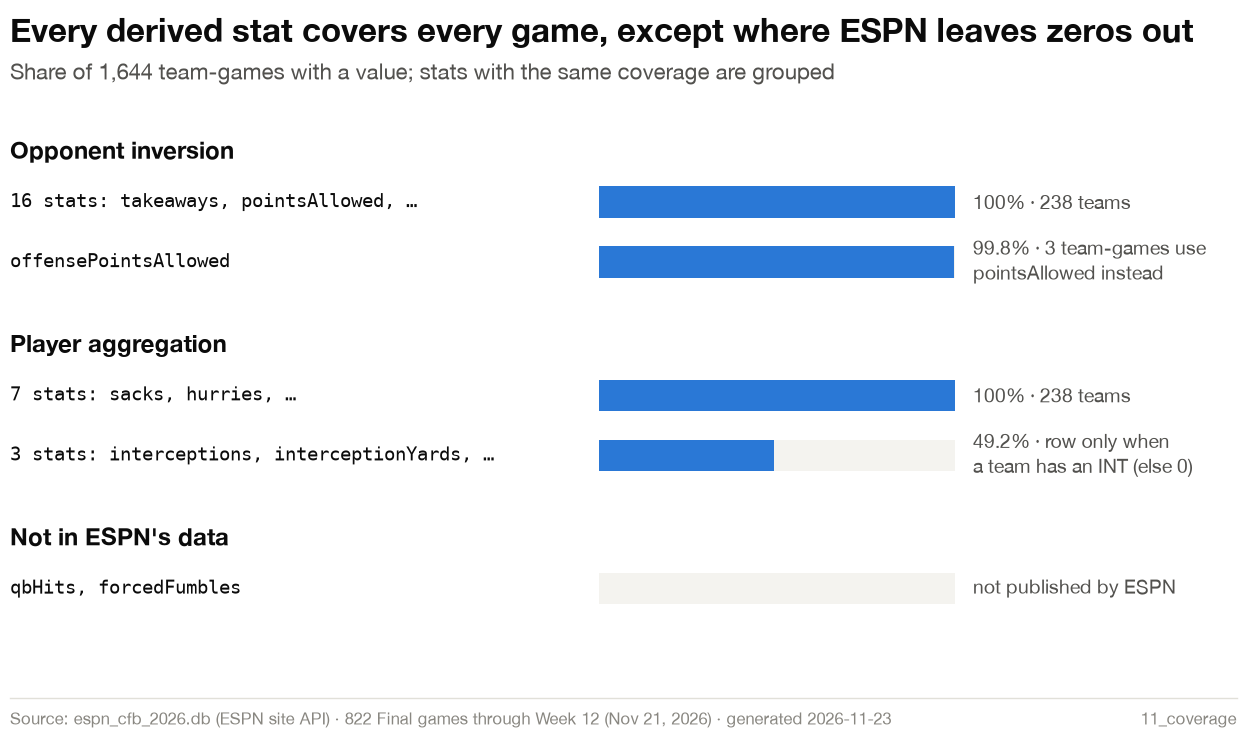

In [51]:
def fig_coverage():
    team_games = facts["team_games"]
    opp = pd.read_sql_query("SELECT stat_name, COUNT(*) AS n, COUNT(DISTINCT team_id) AS teams "
                            "FROM Team_Defense_Opponent_Stats GROUP BY stat_name", conn).assign(method="Opponent inversion")
    ply = pd.read_sql_query("SELECT stat_name, COUNT(*) AS n, COUNT(DISTINCT team_id) AS teams "
                            "FROM Team_Defensive_Stats GROUP BY stat_name", conn).assign(method="Player aggregation")
    published = set(pd.read_sql_query("SELECT DISTINCT stat_name FROM Player_Box_Scores", conn).stat_name)
    absent = pd.DataFrame([{"stat_name": s, "n": 0, "teams": 0, "method": "Not in ESPN's data"}
                           for s in ("qbHits", "forcedFumbles") if s not in published])
    cov = pd.concat([opp, ply, absent], ignore_index=True)
    order = ["Opponent inversion", "Player aggregation", "Not in ESPN's data"]
    groups = (cov.groupby(["method", "n"]).agg(stats=("stat_name", list), teams=("teams", "max")).reset_index())
    groups["order"] = groups.method.map(order.index)
    groups = groups.sort_values(["order", "n"], ascending=[True, False]).reset_index(drop=True)

    def label(stats):
        stats = sorted(stats, key=len)
        return ", ".join(stats) if len(stats) <= 2 else f"{len(stats)} stats: {stats[0]}, {stats[1]}, …"

    fig = new_figure("Every derived stat covers every game, except where ESPN leaves zeros out",
                     f"Share of {team_games:,} team-games with a value; stats with the same coverage are grouped")
    ax = fig.add_axes((0.04, 0.14, 0.92, 0.70))
    ax.set_xlim(0, 100)
    ax.axis("off")
    y = 0
    for method in order:
        rows = groups[groups.method == method]
        if rows.empty:
            continue
        ax.text(0, y, method, fontsize=17, fontweight="bold", color=INK, va="center")
        y -= 1
        for r in rows.itertuples():
            pct = r.n / team_games * 100
            ax.text(0, y, label(sorted(r.stats)), fontsize=14, color=INK, va="center", family="monospace")
            bar_x, bar_w = 48, 29
            ax.add_patch(Rectangle((bar_x, y - 0.3), bar_w, 0.6, fc=PANEL, ec="none"))
            color = ORANGE if r.n == 0 else BLUE
            ax.add_patch(Rectangle((bar_x, y - 0.3), bar_w * pct / 100, 0.6, fc=color, ec="none"))
            if r.n == 0:
                note = "not published by ESPN"
            elif r.n == team_games:
                note = f"{pct:.0f}% · {r.teams} teams"
            elif any(s.startswith("interception") for s in r.stats) and method == "Player aggregation":
                note = f"{pct:.1f}% · row only when\na team has an INT (else 0)"
            else:
                note = f"{pct:.1f}% · {team_games - r.n} team-games use\npointsAllowed instead"
            ax.text(bar_x + bar_w + 1.5, y, note, fontsize=14, color=INK_2, va="center", linespacing=1.1)
            y -= 1.15
        y -= 0.4
    ax.set_ylim(y + 0.6, 0.7)
    full = cov[cov.n == team_games].groupby("method").size()
    fallback = team_games - int(cov.loc[cov.stat_name == "offensePointsAllowed", "n"].iloc[0])
    save(fig, "11_coverage",
         f"{full.get('Opponent inversion', 0)} of {facts['opp_stats']} opponent-derived stats and "
         f"{full.get('Player aggregation', 0)} of {facts['player_team_stats']} player totals cover every team-game; "
         f"offensePointsAllowed falls back to pointsAllowed in {fallback}, interception rows exist only when a team "
         f"has one, and QB hits and forced fumbles are not in ESPN's data.")


fig_coverage()

### Case study and all-teams view

Tennessee's per-game reconstructed defense with the season average from `season_rollup` (section 4), then every FBS team's season values. The case-study cell asserts that the per-game bars average exactly to the rollup.

The issue mentions **288.4** total yards allowed per game for Tennessee from an earlier validation. With the current data through Week 11 the value is shown in the figure title; the two differ because the earlier number came from an older snapshot.

12_case_study_tennessee: Tennessee's reconstructed defense allowed 282.9 total yards and 13.5 offensive points per game, and the per-game values average exactly to the season rollup.


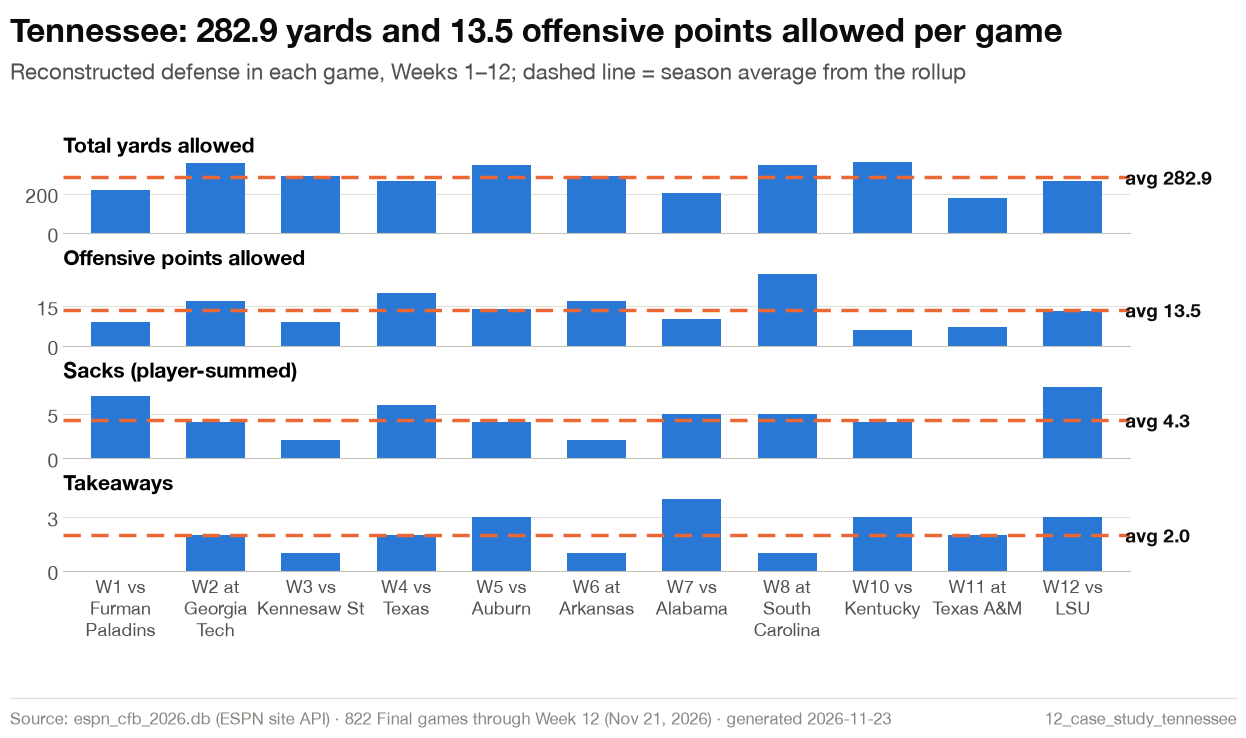

13_fbs_distribution: Among 138 FBS defenses, Tennessee ranks 11th in total yards allowed, 5th in offensive points allowed, 4th in takeaways and 1st in sacks (1st = best).


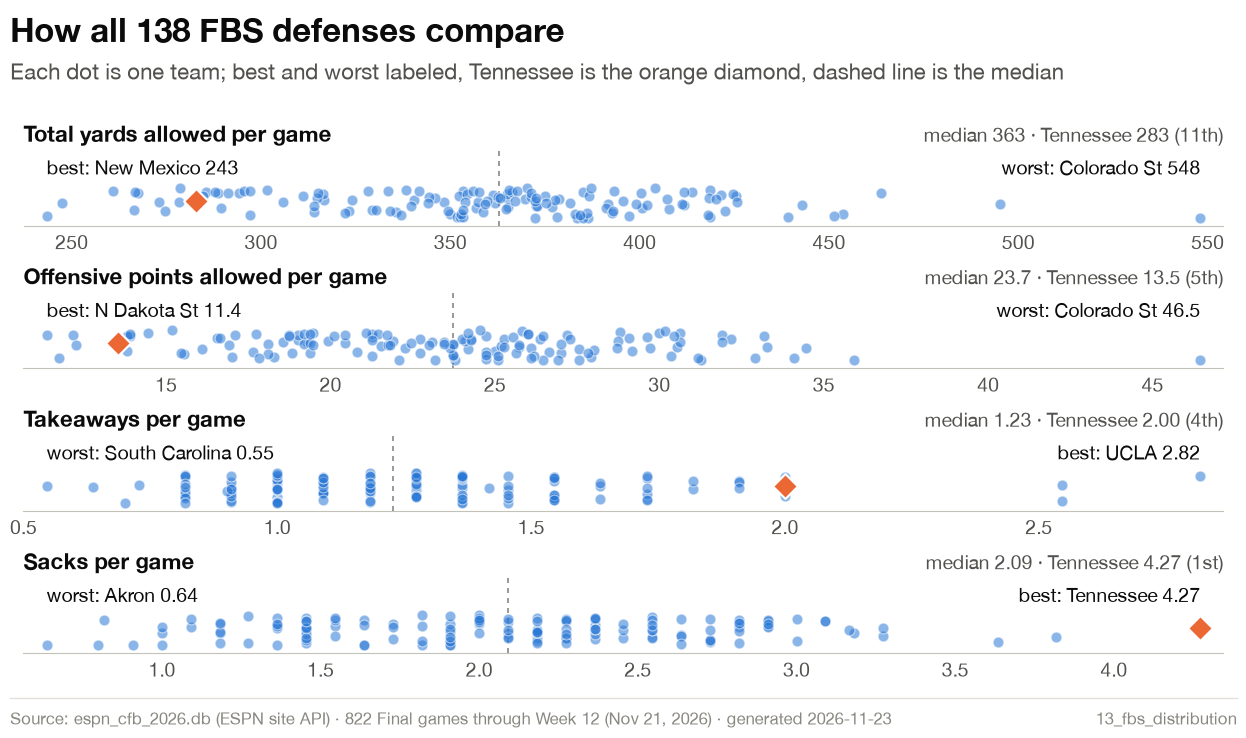

In [52]:
def fig_case_study():
    import textwrap

    rows = pd.read_sql_query("""
        SELECT g.game_id, g.week, d.opponent_id,
               CASE WHEN g.home_team_id = :t THEN 'vs' ELSE 'at' END AS site,
               MAX(CASE WHEN d.stat_name = 'totalYardsAllowed' THEN d.stat_value END) AS totalYardsAllowed,
               COALESCE(MAX(CASE WHEN d.stat_name = 'offensePointsAllowed' THEN d.stat_value END),
                        MAX(CASE WHEN d.stat_name = 'pointsAllowed' THEN d.stat_value END)) AS offensePointsAllowed,
               MAX(CASE WHEN d.stat_name = 'takeaways' THEN d.stat_value END) AS takeaways
        FROM Games g
        JOIN Team_Defense_Opponent_Stats d ON d.game_id = g.game_id AND d.team_id = :t
        WHERE g.status = 'Final'
        GROUP BY g.game_id ORDER BY g.game_date""", conn, params={"t": CASE_TEAM_ID})
    sacks = pd.read_sql_query("SELECT game_id, team_total AS sacks FROM Team_Defensive_Stats "
                              "WHERE team_id = ? AND stat_name = 'sacks'", conn, params=(CASE_TEAM_ID,))
    rows = rows.merge(sacks, on="game_id", how="left").fillna({"sacks": 0})
    season = season_rollup.set_index("team_id").loc[CASE_TEAM_ID]
    avg = {"totalYardsAllowed": season.totalYardsAllowed_per_game,
           "offensePointsAllowed": season.offensePointsAllowed_per_game,
           "sacks": season.player_sacks_per_game,
           "takeaways": season.takeaways_per_game}
    for stat, value in avg.items():   # same average two ways: rollup vs. the per-game rows plotted here
        assert np.isclose(rows[stat].mean(), value), stat

    team = short_names[CASE_TEAM_ID]
    fig = new_figure(f"{team}: {avg['totalYardsAllowed']:.1f} yards and "
                     f"{avg['offensePointsAllowed']:.1f} offensive points allowed per game",
                     f"Reconstructed defense in each game, Weeks 1–{rows.week.max()}; "
                     f"dashed line = season average from the rollup")
    panels = [("totalYardsAllowed", "Total yards allowed", "{:.1f}"),
              ("offensePointsAllowed", "Offensive points allowed", "{:.1f}"),
              ("sacks", "Sacks (player-summed)", "{:.1f}"),
              ("takeaways", "Takeaways", "{:.1f}")]
    xx = np.arange(len(rows))
    for i, (col, title, f) in enumerate(panels):
        ax = fig.add_axes((0.08, 0.68 - i * 0.15, 0.80, 0.10))
        ax.bar(xx, rows[col], color=BLUE, width=0.62)
        ax.axhline(avg[col], color=ORANGE, lw=2.5, ls=(0, (5, 3)))
        ax.text(len(rows) - 0.45, avg[col], f"avg {f.format(avg[col])}", ha="left", va="center", fontsize=14,
                fontweight="bold", color=INK)
        ax.set_title(title, fontsize=15, pad=4)
        ax.set_xlim(-0.6, len(rows) - 0.4)
        style_axes(ax)
        ax.spines["left"].set_visible(False)
        ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(2, integer=True))
        if i == len(panels) - 1:
            ax.set_xticks(xx, [f"W{w} {s}\n" + textwrap.fill(short_names[o], 11)
                               for w, s, o in zip(rows.week, rows.site, rows.opponent_id)], fontsize=13)
        else:
            ax.set_xticks(xx, [""] * len(xx))
    save(fig, "12_case_study_tennessee",
         f"{team}'s reconstructed defense allowed {avg['totalYardsAllowed']:.1f} total yards and "
         f"{avg['offensePointsAllowed']:.1f} offensive points per game, and the per-game values average "
         f"exactly to the season rollup.")


def fig_fbs_distribution():
    s = season_rollup.copy()
    s["short"] = s.team_id.map(short_names)
    stats = [("totalYardsAllowed_per_game", "Total yards allowed per game", False, "{:.0f}"),
             ("offensePointsAllowed_per_game", "Offensive points allowed per game", False, "{:.1f}"),
             ("takeaways_per_game", "Takeaways per game", True, "{:.2f}"),
             ("player_sacks_per_game", "Sacks per game", True, "{:.2f}")]
    fig = new_figure(f"How all {len(s)} FBS defenses compare",
                     f"Each dot is one team; best and worst labeled, {short_names[CASE_TEAM_ID]} is the orange "
                     f"diamond, dashed line is the median")
    jitter = np.random.default_rng(445).uniform(-0.3, 0.3, len(s))
    case = (s.team_id == CASE_TEAM_ID).to_numpy()
    case_ranks = []

    def ordinal(n):
        return f"{n}{'th' if 10 <= n % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th')}"
    for i, (col, title, higher_is_better, f) in enumerate(stats):
        ax = fig.add_axes((0.05, 0.69 - i * 0.19, 0.90, 0.10))
        v = s[col]
        ax.scatter(v[~case], jitter[~case], s=60, color=BLUE, alpha=0.55, edgecolor="white", linewidth=0.8)
        ax.scatter(v[case], jitter[case], s=160, color=ORANGE, marker="D", edgecolor="white", linewidth=1.5, zorder=3)
        ax.axvline(v.median(), color=MUTED, lw=1.2, ls=(0, (3, 3)), zorder=0)
        lo, hi = v.min(), v.max()
        ax.set_xlim(lo - (hi - lo) * 0.02, hi + (hi - lo) * 0.02)
        ax.set_ylim(-0.45, 1.0)
        ax.set_yticks([])
        ax.spines["left"].set_visible(False)
        ax.tick_params(length=0)
        best = s.loc[v.idxmax() if higher_is_better else v.idxmin()]
        worst = s.loc[v.idxmin() if higher_is_better else v.idxmax()]
        for team, tag in ((best, "best"), (worst, "worst")):
            x = team[col]
            ax.text(x, 0.68, f"{tag}: {team.short} {f.format(x)}", fontsize=14, color=INK, va="center",
                    ha="left" if x == lo else "right")
        ax.text(0, 1.12, title, transform=ax.transAxes, fontsize=16, fontweight="bold", color=INK)
        rank = int(v.rank(ascending=not higher_is_better, method="min")[case].iloc[0])
        case_ranks.append((title.replace(" per game", "").lower(), rank))
        ax.text(1, 1.12, f"median {f.format(v.median())} · {short_names[CASE_TEAM_ID]} "
                         f"{f.format(v[case].iloc[0])} ({ordinal(rank)})", transform=ax.transAxes, fontsize=14,
                color=INK_2, ha="right")
    ranks_text = ", ".join(f"{ordinal(r)} in {name}" for name, r in case_ranks[:-1])
    save(fig, "13_fbs_distribution",
         f"Among {len(s)} FBS defenses, {short_names[CASE_TEAM_ID]} ranks {ranks_text} and "
         f"{ordinal(case_ranks[-1][1])} in {case_ranks[-1][0]} (1st = best).")


fig_case_study()
fig_fbs_distribution()

### Slide 8: defensive rankings

Raw rank (`defense_rankings`, section 5) against the CFP-weighted, opponent-adjusted rank (`cfp_defense_rankings`, section 7) for every team in either top 10.

14_ranking_movers: With CFP weights and opponent adjustment, Notre Dame moves from 8 to 1 while raw leader New Mexico falls to 11.


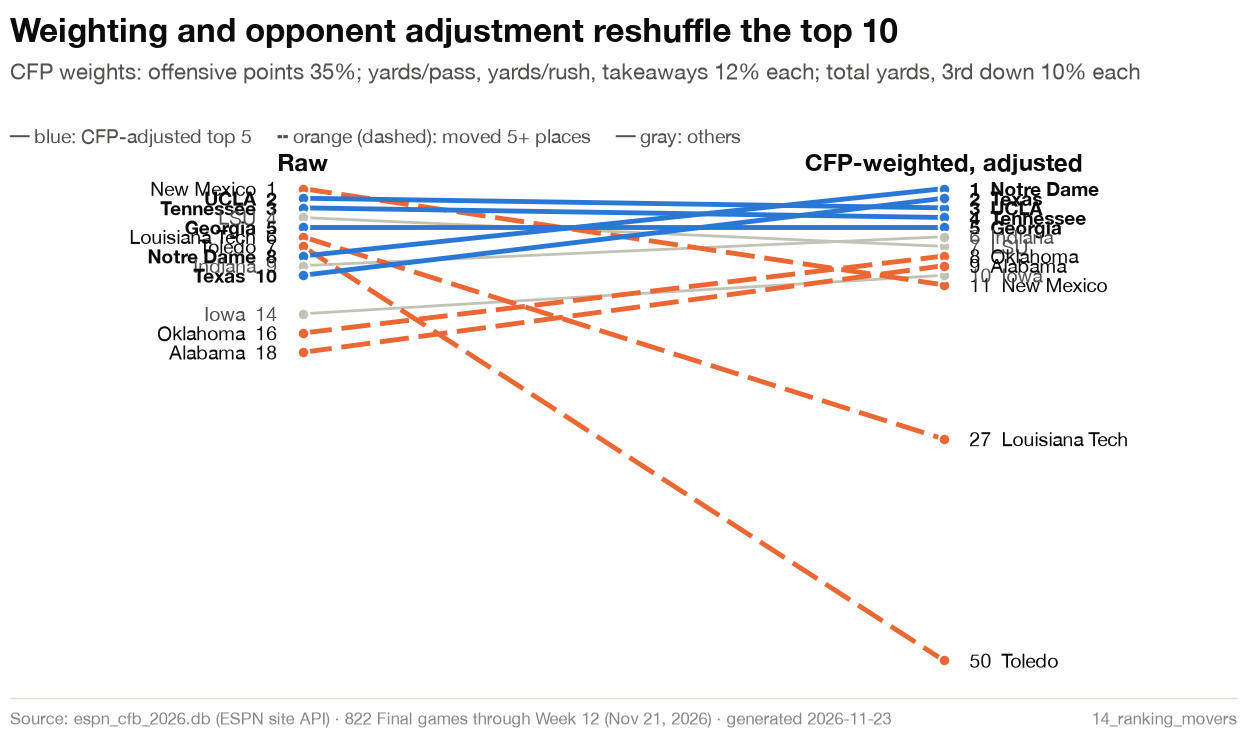

,short,raw_rank,cfp_rank,change
7,Notre Dame,8,1,7
9,Texas,10,2,8
1,UCLA,2,3,-1
2,Tennessee,3,4,-1
4,Georgia,5,5,0
8,Indiana,9,6,3
3,LSU,4,7,-3
15,Oklahoma,16,8,8
17,Alabama,18,9,9
13,Iowa,14,10,4


In [53]:
def fig_ranking_movers():
    raw = defense_rankings[["team_id"]].assign(raw_rank=defense_rankings.index)
    cfp = cfp_defense_rankings[["team_id"]].assign(cfp_rank=cfp_defense_rankings.index)
    ranks = raw.merge(cfp, on="team_id")
    ranks["short"] = ranks.team_id.map(short_names)
    show = ranks[(ranks.raw_rank <= 10) | (ranks.cfp_rank <= 10)]
    lowest = int(show[["raw_rank", "cfp_rank"]].max().max())

    fig = new_figure("Weighting and opponent adjustment reshuffle the top 10",
                     "CFP weights: offensive points 35%; yards/pass, yards/rush, takeaways 12% each; "
                     "total yards, 3rd down 10% each")
    ax = fig.add_axes((0.25, 0.10, 0.50, 0.66))
    for r in show.itertuples():
        top5, moved = r.cfp_rank <= 5, abs(r.raw_rank - r.cfp_rank) >= 5
        color = BLUE if top5 else (ORANGE if moved else AXIS)
        emphasis = top5 or moved
        ax.plot([0, 1], [r.raw_rank, r.cfp_rank], color=color, lw=3.5 if emphasis else 2, zorder=3 if emphasis else 2,
                ls="-" if top5 or not moved else (0, (6, 2)))
        ax.scatter([0, 1], [r.raw_rank, r.cfp_rank], s=70, color=color, zorder=4, edgecolor="white", linewidth=1.5)
        weight, ink = ("bold" if top5 else "normal"), (INK if emphasis else INK_2)
        ax.text(-0.04, r.raw_rank, f"{r.short}  {r.raw_rank}", ha="right", va="center", fontsize=14,
                fontweight=weight, color=ink)
        ax.text(1.04, r.cfp_rank, f"{r.cfp_rank}  {r.short}", ha="left", va="center", fontsize=14,
                fontweight=weight, color=ink)
    ax.set_ylim(lowest + 0.8, -0.6)
    ax.set_xlim(-0.02, 1.02)
    ax.axis("off")
    ax.text(0, -0.3, "Raw", ha="center", va="bottom", fontsize=17, fontweight="bold", color=INK)
    ax.text(1, -0.3, "CFP-weighted, adjusted", ha="center", va="bottom", fontsize=17, fontweight="bold", color=INK)
    fig.text(0.04, 0.80, "━ blue: CFP-adjusted top 5     ╍ orange (dashed): moved 5+ places     ━ gray: others",
             fontsize=14, color=INK_2)
    top = ranks.sort_values("cfp_rank").iloc[0]
    raw_leader = ranks.sort_values("raw_rank").iloc[0]
    save(fig, "14_ranking_movers",
         f"With CFP weights and opponent adjustment, {top.short} moves from {top.raw_rank} to 1 while raw leader "
         f"{raw_leader.short} falls to {raw_leader.cfp_rank}.")
    return ranks


ranking_moves = fig_ranking_movers()
display(ranking_moves.assign(change=ranking_moves.raw_rank - ranking_moves.cfp_rank)
        .sort_values("cfp_rank").head(10)[["short", "raw_rank", "cfp_rank", "change"]])

In [54]:
# Captions file: one line per figure with its takeaway.
lines = ["# Presentation figures", "",
         f"{FOOTER}. Regenerate by running cfb{YEAR}_stats.ipynb from the top.", ""]
lines += [f"- **{name}** (`{name}.png`, `{name}.svg`): {caption}" for name, caption in CAPTIONS.items()]
(FIG_DIR / "captions.md").write_text("\n".join(lines) + "\n")
print(f"Wrote {len(CAPTIONS)} figures (PNG + SVG) and captions.md to {FIG_DIR}/")

Wrote 14 figures (PNG + SVG) and captions.md to figures/
